In [1]:
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from matplotlib.ticker import FormatStrFormatter
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, cross_validate, cross_val_score
from sklearn.metrics import confusion_matrix 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

In [2]:
ga = pd.read_csv('data/ga_sessions.csv', low_memory=False)
print(ga.shape)
ga.head()

(1860042, 18)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow


In [3]:
ga.describe().map(lambda x: f"{x:.4f}")

,visit_number
count,1860042.0000
mean,2.7128
std,11.8291
min,1.0000
25%,1.0000
50%,1.0000
75%,2.0000
max,564.0000


In [4]:
ga.describe(include='O')

,session_id,client_id,visit_date,visit_time,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
count,1860042,1860042,1860042,1860042,1859945,1860042,1640439,1524427,777981,1860042,789904,1492864,16338,1860042,1860042,1860042,1860042
unique,1860042,1391719,226,85318,293,56,412,286,1219,3,13,205,104,5039,57,166,2548
top,9055434745589932991.1637753792.1637753792,1750498477.1629450062,2021-05-24,12:00:00,ZpYIoDJMcFzVoPFsHGJL,banner,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Apple,AuMdmADEIoPXiWpTsBEj,414x896,Chrome,Russia,Moscow
freq,1,462,39453,61067,578290,552272,463481,1006599,506819,1474871,464054,551088,9778,169090,1013436,1800565,805329


In [5]:
ga_hits = pd.read_csv('data/ga_hits-001.csv')
print(ga_hits.shape)
ga_hits.head()

(15726470, 11)


,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,NaN
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,NaN
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,NaN
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,NaN
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,NaN


In [6]:
ga_hits.describe().map(lambda x: f"{x:.4f}")

,hit_time,hit_number,event_value
count,6566148.0000,15726470.0000,0.0000
mean,209104.9892,23.5671,nan
std,403210.9723,28.8771,nan
min,0.0000,1.0000,nan
25%,24120.0000,7.0000,nan
50%,89941.0000,15.0000,nan
75%,219535.2500,29.0000,nan
max,13156885.0000,500.0000,nan


In [7]:
ga_hits.describe(include='O')

,session_id,hit_date,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label
count,15726470,15726470,15726470,9451666,15726470,15726470,15726470,11966286
unique,1734610,226,1,37873,342715,52,230,39825
top,5442565791571325612.1632449195.1632449195,2021-05-24,event,HbolMJUevblAbkHClEQa,podpiska.sberauto.com/,card_web,view_card,KclpemfoHstknWHFiLit
freq,768,513035,15726470,8879187,2793639,7456998,3558985,6505447


## Data Preparation

### Формирование единого датасета для дальнейшей обработки

In [8]:
target_action =  ['sub_car_claim_click', 'sub_car_claim_submit_click', 'sub_open_dialog_click', 'sub_custom_question_submit_click', 
                  'sub_call_number_click', 'sub_callback_submit_click', 'sub_submit_success', 'sub_car_request_submit_click']

In [9]:
# Проставление признака совершения события пользователем в датасете GA Hits на основе указанных в задании целевых действий

ga_hits.event_value = ga_hits.event_action.apply(lambda x: 1 if x in target_action else 0)
ga_hits.head()

,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,0
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,0
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,0
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,0
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,0


In [10]:
# Формирование словаря сессий и событий

ga_hits_agr = ga_hits.groupby(['session_id'])[['event_value']].max()
ga_hits_agr

,event_value
session_id,
1000009318903347362.1632663668.1632663668,0
1000010177899156286.1635013443.1635013443,0
1000013386240115915.1635402956.1635402956,0
1000017303238376207.1623489300.1623489300,0
1000020580299877109.1624943350.1624943350,0
...,...
999960188766601545.1626816843.1626816843,0
99996598443387715.1626811203.1626811203,0
999966717128502952.1638428330.1638428330,0


In [11]:
# Создание колонки событий в датасете GA Sessions

ga['event_session_target'] = ga.session_id.apply(lambda x: ga_hits_agr.loc[x, 'event_value']
                                                               if x in ga_hits_agr.index else -1)

In [12]:
# Удаление строк с сессиями, которые не содержатся в датасете GA Sessions

ga_tg = ga[ga.event_session_target!=-1]
print(ga_tg.shape)
ga_tg.head()

(1732266, 19)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,event_session_target
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust,0
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow,0
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk,0
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0


In [13]:
# Проверка наличия дублирующих строк

ga_tg.duplicated().sum()

np.int64(0)

### Заполнение пустых значений в датасете

In [14]:
ga_tg.isna().sum()

session_id                        0
client_id                         0
visit_date                        0
visit_time                        0
visit_number                      0
utm_source                       76
utm_medium                        0
utm_campaign                 195287
utm_adcontent                304137
utm_keyword                 1020752
device_category                   0
device_os                   1013964
device_brand                 347196
device_model                1717204
device_screen_resolution          0
device_browser                    0
geo_country                       0
geo_city                          0
event_session_target              0
dtype: int64

In [15]:
ga_tg.isna().sum()/ga_tg.shape[0] * 100

session_id                   0.000000
client_id                    0.000000
visit_date                   0.000000
visit_time                   0.000000
visit_number                 0.000000
utm_source                   0.004387
utm_medium                   0.000000
utm_campaign                11.273500
utm_adcontent               17.557177
utm_keyword                 58.925823
device_category              0.000000
device_os                   58.533966
device_brand                20.042880
device_model                99.130503
device_screen_resolution     0.000000
device_browser               0.000000
geo_country                  0.000000
geo_city                     0.000000
event_session_target         0.000000
dtype: float64

#### Заполнение пропусков в колонках device_os, device_brand

##### <span style="color: brown;"> Обновление device_os на уровне информации о клиенте</spam>

In [16]:
# Формирование словаря на основе данных по клиенту

ga_tg_clients = ga_tg[((ga_tg.device_brand.isna()) | (ga_tg.device_os.isna()))].client_id.drop_duplicates()

ga_tg_agg = ga_tg[ga_tg.client_id.isin(ga_tg_clients) ].groupby([
    'client_id', 'device_category', 'device_brand', 'device_os', 'device_browser', 'device_screen_resolution'], 
                                                                as_index=False).agg(count_session = ('session_id', 'count'))

ga_tg_agg_max_for_os = ga_tg_agg.groupby(['client_id', 'device_category', 'device_brand', 'device_browser', 'device_screen_resolution'])['count_session'].idxmax()
ga_tg_agg_dict_for_os = ga_tg_agg.loc[ga_tg_agg_max_for_os]
ga_tg_agg_dict_for_os = ga_tg_agg_dict_for_os.rename(columns={'device_os': 'device_os_dict_by_client'})
ga_tg_agg_dict_for_os

,client_id,device_category,device_brand,device_os_dict_by_client,device_browser,device_screen_resolution,count_session
0,1000065455.1633104154,mobile,Huawei,Android,Chrome,360x760,1
1,1000104178.1634292815,mobile,Apple,iOS,Safari,375x667,1
2,1000132981.1621847002,mobile,Huawei,Android,Chrome,360x780,1
3,1000186405.1632665539,mobile,Huawei,Android,YaBrowser,320x694,1
4,1000207388.1634728142,mobile,Xiaomi,Android,Chrome,360x800,1
...,...,...,...,...,...,...,...
15015,99933873.1632403065,mobile,Apple,iOS,Safari,414x896,1
15016,999573066.1633605740,mobile,Xiaomi,Android,Chrome,360x760,2
15017,999658444.1629807384,mobile,Xiaomi,Android,Chrome,393x851,6
15018,999786309.1631085787,mobile,Xiaomi,Android,Chrome,360x800,1


In [17]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left= ga_tg, 
                 right=ga_tg_agg_dict_for_os, 
                 on=['client_id', 'device_category', 'device_brand', 'device_browser', 'device_screen_resolution'],
                 how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 19)
(1732266, 21)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,event_session_target,device_os_dict_by_client,count_session
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust,0,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow,0,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk,0,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,...,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,...,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0,NaN,NaN


In [18]:
# Заполнение пустых значений в колонке device_os значениями из словаря

ga_tg.loc[(~ga_tg.device_brand.isna()) & 
          (ga_tg.device_os.isna()) &
          (~ga_tg.device_os_dict_by_client.isna()), 'device_os'] = ga_tg.device_os_dict_by_client
ga_tg.device_os.isna().sum()

np.int64(983914)

##### <span style="color: brown;"> Заполнение колонок device_os и device_brand для устройств Apple </spam>

In [19]:
ga_tg[
    ((ga_tg.device_brand=='Apple') |
    (ga_tg.device_os.isin(['Macintosh','iOS'])) |
    (ga_tg.device_browser.isin(['Safari', 'Safari (in-app)'])))
    ].groupby(['device_category', 'device_brand', 'device_os', 
               'device_browser'], dropna=False).agg(count = ('device_browser', 'count'))

count
device_category device_brand device_os     device_browser                  
desktop         Apple        iOS           Chrome                         3
                                           Safari                        28
                             NaN           Chrome                         3
                                           Safari                        36
                NaN          Linux         Safari                         5
                             Macintosh     Chrome                      9224
                                           Edge                          69
                                           Firefox                      281
                                           Mozilla Compatible Agent      16
                                           Opera                        201
                                           Safari                     12638
                                           YaBrowser                    966
                             NaN           Safari                     25985
mobile          (not set)    iOS           Safari                         5
                             NaN           Safari                         1
                Apple        iOS           Chrome                      6655
                                           Instagram 213.0.0.19.117       3
                                           Instagram 216.0.0.12.135       4
                                           Iron                           1
                                           MyApp                          1
                                           Safari                    159797
                                           Safari (in-app)            13929
                                           UC Browser                     1
                                           YaBrowser                   4607
                             NaN           Chrome                     15405
                                           Edge                           1
                                           Instagram 192.0.0.37.119       6
                                           Instagram 199.0.0.27.120       2
                                           Instagram 201.0.0.23.111       5
                                           Instagram 202.0.0.23.119      17
                                           Instagram 203.0.0.26.117       6
                                           Instagram 207.0.0.28.118       4
                                           Instagram 208.0.0.26.131       2
                                           Iron                           1
                                           MyApp                          1
                                           Safari                    235090
                                           Safari (in-app)            51344
                                           UC Browser                    15
                                           YaBrowser                  10783
                Microsoft    NaN           Safari                         1
                Nokia        Windows Phone Safari                         1
                             NaN           Safari                         3
                NaN          Macintosh     Chrome                         2
                                           Safari                         7
                                           YaBrowser                      1
                             NaN           Safari                        15
tablet          Apple        iOS           Chrome                       365
                                           Safari                       933
                                           Safari (in-app)              152
                                           YaBrowser                    289
                             NaN           Chrome                       894
                                          

In [20]:
def update_apple_data(data): 

    data.loc[
        (data.device_category=='desktop') &
        (data.device_brand=='Apple') &
        (data.device_os.isna()), 'device_os'] = 'Macintosh'

    data.loc[
        (data.device_category=='desktop') &
        (data.device_brand.isna()) &
        (data.device_os=='Macintosh'), 'device_brand'] = 'Apple'
    
    data.loc[
        (data.device_category=='desktop') &
        (data.device_os.isna()) &
        (data.device_brand.isna()) &
        (data.device_browser=='Safari'), ['device_brand','device_os']] = ['Apple', 'Macintosh']

    data.loc[
        (data.device_category.isin(['mobile', 'tablet'])) &  
        (data.device_os=='iOS') &
        (data.device_brand.isna()), 'device_brand'] = 'Apple'    

    data.loc[
        (data.device_category.isin(['mobile', 'tablet'])) &    
        (data.device_os.isna()) &
        (data.device_brand=='Apple'), 'device_os'] = 'iOS' 

    data.loc[
        (data.device_category.isin(['mobile', 'tablet'])) & 
        (data.device_os.isna()) &
        (data.device_brand.isna()) &
        (data.device_browser.isin(['Safari', 'Safari (in-app)'])), ['device_brand','device_os']] = ['Apple', 'iOS']


In [21]:
update_apple_data(ga_tg)
print(ga_tg.shape)
ga_tg.head()

(1732266, 21)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,event_session_target,device_os_dict_by_client,count_session
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust,0,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow,0,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk,0,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,...,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,...,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0,NaN,NaN


In [22]:
ga_tg[
    ((ga_tg.device_brand=='Apple') |
    (ga_tg.device_os.isin(['Macintosh','iOS'])) |
    (ga_tg.device_browser.isin(['Safari', 'Safari (in-app)'])))
    ].groupby(['device_category', 'device_brand', 'device_os', 
               'device_browser'], dropna=False).agg(count = ('device_browser', 'count'))

count
device_category device_brand device_os     device_browser                  
desktop         Apple        Macintosh     Chrome                      9227
                                           Edge                          69
                                           Firefox                      281
                                           Mozilla Compatible Agent      16
                                           Opera                        201
                                           Safari                     38659
                                           YaBrowser                    966
                             iOS           Chrome                         3
                                           Safari                        28
                NaN          Linux         Safari                         5
mobile          (not set)    iOS           Safari                         5
                             NaN           Safari                         1
                Apple        iOS           Chrome                     22060
                                           Edge                           1
                                           Instagram 192.0.0.37.119       6
                                           Instagram 199.0.0.27.120       2
                                           Instagram 201.0.0.23.111       5
                                           Instagram 202.0.0.23.119      17
                                           Instagram 203.0.0.26.117       6
                                           Instagram 207.0.0.28.118       4
                                           Instagram 208.0.0.26.131       2
                                           Instagram 213.0.0.19.117       3
                                           Instagram 216.0.0.12.135       4
                                           Iron                           2
                                           MyApp                          2
                                           Safari                    394902
                                           Safari (in-app)            65273
                                           UC Browser                    16
                                           YaBrowser                  15390
                Microsoft    NaN           Safari                         1
                Nokia        Windows Phone Safari                         1
                             NaN           Safari                         3
                NaN          Macintosh     Chrome                         2
                                           Safari                         7
                                           YaBrowser                      1
tablet          Apple        iOS           Chrome                      1259
                                           Safari                      3083
                                           Safari (in-app)              679
                                           YaBrowser                    867
                NaN          Macintosh     Safari                        10

In [23]:
ga_tg.device_os.isna().sum()

np.int64(641044)

In [24]:
ga_tg.device_brand.isna().sum()

np.int64(297696)

##### <span style="color: brown;"> Заполнение колонки device_os по бренду </spam>

In [25]:
# Формирование словаря на основе данных по бренду

ga_tg_agg_os_by_brand = ga_tg[~ga_tg.device_brand.isin(['Apple', '(not set)'])].groupby(
    ['device_category', 'device_brand', 'device_os'], as_index=False).agg(count_sessions = ('session_id', 'count'))

ga_tg_agg_os_by_brand_max = ga_tg_agg_os_by_brand.groupby(['device_category', 'device_brand'])['count_sessions'].idxmax()
ga_tg_agg_os_by_brand_dict = ga_tg_agg_os_by_brand.loc[ga_tg_agg_os_by_brand_max]
ga_tg_agg_os_by_brand_dict = ga_tg_agg_os_by_brand_dict.rename(columns={'device_os': 'device_os_dict_by_brand'})
ga_tg_agg_os_by_brand_dict

,device_category,device_brand,device_os_dict_by_brand,count_sessions
0,desktop,Flexymove,Android,3
1,desktop,Google,Android,4
2,desktop,Huawei,Android,3
3,desktop,Realme,Android,1
4,desktop,Samsung,Android,3
...,...,...,...,...
191,tablet,TurboPad,Android,3
192,tablet,UGOOS,Android,2
193,tablet,Wexler,Android,1
194,tablet,Xiaomi,Android,81


In [26]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg,
                right=ga_tg_agg_os_by_brand_dict,
                on=['device_category', 'device_brand'],
                how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 21)
(1732266, 23)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,device_model,device_screen_resolution,device_browser,geo_country,geo_city,event_session_target,device_os_dict_by_client,count_session,device_os_dict_by_brand,count_sessions
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,360x720,Chrome,Russia,Zlatoust,0,NaN,NaN,Android,85874.0
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,NaN,385x854,Samsung Internet,Russia,Moscow,0,NaN,NaN,Android,160723.0
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,360x720,Chrome,Russia,Krasnoyarsk,0,NaN,NaN,Android,85874.0
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,...,NaN,393x786,Chrome,Russia,Moscow,0,NaN,NaN,Android,136150.0
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,...,NaN,393x786,Chrome,Russia,Moscow,0,NaN,NaN,Android,136150.0


In [27]:
# Заполнение пустых значений в колонке device_os значениями из словаря

ga_tg.loc[
    (~ga_tg.device_brand.isna()) &
    (ga_tg.device_os.isna()) &
    (~ga_tg.device_os_dict_by_brand.isna()), 'device_os'] = ga_tg.device_os_dict_by_brand

In [28]:
ga_tg.device_os.isna().sum()

np.int64(218103)

##### <span style="color: brown;"> Одновременное заполнение колонок device_os и device_brand по клиенту </spam>

In [29]:
# Формирование словаря на основе данных по клиенту

ga_tg_na_brand_os = ga_tg[(ga_tg.device_brand.isna()) & (ga_tg.device_os.isna()) 
    ].groupby(['device_category', 'client_id', 'device_brand', 'device_os', 'device_screen_resolution'], 
              dropna=False, as_index=False).agg(count_session = ('session_id', 'count'))

ga_tg_na_brand_os_client = ga_tg[
    (ga_tg.device_category + ' ' + ga_tg.client_id + ' ' + ga_tg.device_screen_resolution).isin(
        ga_tg_na_brand_os.device_category + ' ' + ga_tg_na_brand_os.client_id + ' ' + ga_tg_na_brand_os.device_screen_resolution)
    ].groupby(['device_category', 'client_id', 'device_brand', 'device_os', 'device_screen_resolution'], 
              as_index=False).agg(count_session = ('session_id', 'count'))

ga_tg_na_brand_os_client_max = ga_tg_na_brand_os_client.groupby(['device_category', 'client_id', 'device_screen_resolution'])['count_session'].idxmax()
ga_tg_na_brand_os_client_dict = ga_tg_na_brand_os_client.loc[ga_tg_na_brand_os_client_max]
ga_tg_na_brand_os_client_dict = ga_tg_na_brand_os_client_dict.rename(columns={'device_brand': 'device_brand_dict_cl_br_os',
                                                                              'device_os': 'device_os_cl_br_os'})
ga_tg_na_brand_os_client_dict

,device_category,client_id,device_brand_dict_cl_br_os,device_os_cl_br_os,device_screen_resolution,count_session
0,desktop,1001941830.1621805878,Apple,Macintosh,1440x900,2
1,desktop,1008586126.1633964274,Apple,Macintosh,1440x900,5
2,desktop,1010405362.1631632240,Apple,Macintosh,1440x900,1
3,desktop,101933016.1631117808,Apple,Macintosh,1440x900,6
4,desktop,1022062060.1633969706,Apple,Macintosh,1440x900,3
...,...,...,...,...,...,...
329,mobile,4147558.1629749268,Xiaomi,Android,360x640,1
330,mobile,421161322.1631377206,Xiaomi,Android,393x851,1
331,mobile,58545278.1624642464,Xiaomi,Android,393x830,1
332,tablet,1541280790.1622326489,Samsung,Android,800x1334,1


In [30]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg,
                right=ga_tg_na_brand_os_client_dict,
                on=['device_category', 'client_id', 'device_screen_resolution'],
                how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 23)
(1732266, 26)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,geo_country,geo_city,event_session_target,device_os_dict_by_client,count_session_x,device_os_dict_by_brand,count_sessions,device_brand_dict_cl_br_os,device_os_cl_br_os,count_session_y
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Russia,Zlatoust,0,NaN,NaN,Android,85874.0,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,Russia,Moscow,0,NaN,NaN,Android,160723.0,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Russia,Krasnoyarsk,0,NaN,NaN,Android,85874.0,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,...,Russia,Moscow,0,NaN,NaN,Android,136150.0,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,...,Russia,Moscow,0,NaN,NaN,Android,136150.0,NaN,NaN,NaN


In [31]:
# Заполнение пустых значений в колонках device_os, device_brand значениями из словаря

ga_tg.loc[(ga_tg.device_os.isna()) &  (ga_tg.device_brand.isna()), 
    ['device_os','device_brand']] = ga_tg.loc[
                          (ga_tg.device_os.isna()) & (ga_tg.device_brand.isna()), ['device_os_cl_br_os', 'device_brand_dict_cl_br_os']].values

In [32]:
ga_tg.device_brand.isna().sum()

np.int64(296119)

In [33]:
ga_tg.device_os.isna().sum()

np.int64(216526)

##### <span style="color: brown;"> Заполнение колонки device_os </spam>

In [34]:
# Формирование словаря на основе данных по клиенту

ga_tg_na_brand_os_os = ga_tg[(ga_tg.device_brand.isna()) &  (ga_tg.device_os.isna()) 
    ].groupby(['device_category', 'client_id', 'device_brand', 'device_os', 'device_screen_resolution'], 
              dropna=False, as_index=False).agg(count_session = ('session_id', 'count'))

ga_tg_na_brand_os_os_client = ga_tg[
    (~ga_tg.device_os.isna()) &
    (ga_tg.device_brand.isna()) &    
    ((ga_tg.device_category + ' ' + ga_tg.client_id).isin(
        ga_tg_na_brand_os_os.device_category + ' ' + ga_tg_na_brand_os_os.client_id))
    ].groupby(['device_category', 'client_id', 'device_os', 'device_screen_resolution'], 
              as_index=False).agg(count_session_3 = ('session_id', 'count'))

ga_tg_na_brand_os_os_client_max = ga_tg_na_brand_os_os_client.groupby([
    'device_category', 'client_id', 'device_screen_resolution'])['count_session_3'].idxmax()
ga_tg_na_brand_os_os_client_dict = ga_tg_na_brand_os_os_client.loc[ga_tg_na_brand_os_os_client_max]
ga_tg_na_brand_os_os_client_dict = ga_tg_na_brand_os_os_client_dict.rename(columns={'device_os': 'device_os_dict_os_by_res'})
ga_tg_na_brand_os_os_client_dict

,device_category,client_id,device_os_dict_os_by_res,device_screen_resolution,count_session_3
0,desktop,1000633953.1634550139,Windows,1280x720,1
1,desktop,1000651957.1632482704,Windows,1366x768,1
2,desktop,1001006259.1632552656,Windows,1366x768,1
3,desktop,1002686821.1634893759,Windows,1920x1080,2
4,desktop,100284388.1620244265,Windows,1280x720,4
...,...,...,...,...,...
2170,desktop,995886505.1632343764,Windows,1366x768,1
2171,desktop,995994941.1632171953,Windows,1536x864,1
2172,desktop,996890464.1624455865,Windows,1536x864,3
2173,desktop,997460370.1622971322,Windows,1920x1080,1


In [35]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg,
                right=ga_tg_na_brand_os_os_client_dict,
                on=['device_category', 'client_id', 'device_screen_resolution'],
                how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 26)
(1732266, 28)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,event_session_target,device_os_dict_by_client,count_session_x,device_os_dict_by_brand,count_sessions,device_brand_dict_cl_br_os,device_os_cl_br_os,count_session_y,device_os_dict_os_by_res,count_session_3
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,NaN,NaN,Android,85874.0,NaN,NaN,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,0,NaN,NaN,Android,160723.0,NaN,NaN,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,NaN,NaN,Android,85874.0,NaN,NaN,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,...,0,NaN,NaN,Android,136150.0,NaN,NaN,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,...,0,NaN,NaN,Android,136150.0,NaN,NaN,NaN,NaN,NaN


In [36]:
# Заполнение пустых значений в колонке device_os значениями из словаря

ga_tg.loc[
    (ga_tg.device_brand.isna()) &
    (ga_tg.device_os.isna()) &
    (~ga_tg.device_os_dict_os_by_res.isna()), 'device_os'] = ga_tg.device_os_dict_os_by_res

In [37]:
ga_tg.device_os.isna().sum()

np.int64(205184)

In [38]:
ga_tg.columns

Index(['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number',
       'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent',
       'utm_keyword', 'device_category', 'device_os', 'device_brand',
       'device_model', 'device_screen_resolution', 'device_browser',
       'geo_country', 'geo_city', 'event_session_target',
       'device_os_dict_by_client', 'count_session_x',
       'device_os_dict_by_brand', 'count_sessions',
       'device_brand_dict_cl_br_os', 'device_os_cl_br_os', 'count_session_y',
       'device_os_dict_os_by_res', 'count_session_3'],
      dtype='object')

In [39]:
# Удаление вспомогательных колонок

ga_tg = ga_tg.drop(columns=['device_os_dict_by_client', 'count_session_x', 'device_os_dict_by_brand', 'count_sessions',
                                'device_brand_dict_cl_br_os', 'device_os_cl_br_os', 'count_session_y', 'device_os_dict_os_by_res', 'count_session_3'])

print(ga_tg.shape)
ga_tg.head()

(1732266, 19)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,event_session_target
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust,0
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow,0
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk,0
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,Android,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,Android,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0


In [40]:
# ga_tg_device = ga_tg.copy()

#### Заполнение пропусков в UTM колонках 

In [41]:
ga_tg.isna().sum()

session_id                        0
client_id                         0
visit_date                        0
visit_time                        0
visit_number                      0
utm_source                       76
utm_medium                        0
utm_campaign                 195287
utm_adcontent                304137
utm_keyword                 1020752
device_category                   0
device_os                    205184
device_brand                 296119
device_model                1717204
device_screen_resolution          0
device_browser                    0
geo_country                       0
geo_city                          0
event_session_target              0
dtype: int64

In [42]:
# Создание колонки visit_hour в качестве характкристики для заполнения пустых UTM значений и для дальнейшего анализа

ga_tg['visit_hour'] = ga_tg.visit_time.apply(lambda x: int(x.split(':')[0]))
ga_tg[['visit_time', 'visit_hour']]

,visit_time,visit_hour
0,14:36:32,14
1,08:21:30,8
2,02:42:06,2
3,05:00:00,5
4,05:00:00,5
...,...,...
1732261,10:48:25,10
1732262,08:00:00,8
1732263,15:31:55,15
1732264,15:36:44,15


In [43]:
# Заполнение пустых UTM значений значением _none_ для упрощения обновления данных

ga_tg[['utm_source', 'utm_campaign', 'utm_adcontent', 'utm_keyword']] = ga_tg[
    ['utm_source', 'utm_campaign', 'utm_adcontent', 'utm_keyword']].fillna('_none_')

##### <span style="color: brown;"> Заполнение колонок utm_campaign и utm_adcontent по клиенту </spam>

In [44]:
# Формирование словаря на основе данных колонок client_id, visit_date, visit_hour

ga_tg_utm_cl_1 = ga_tg[(ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_')].groupby(
    ['client_id','utm_medium', 'utm_source', 'utm_keyword'], dropna=False).agg(count_sessions = ('session_id', 'count'))

ga_tg_ind_1 = ga_tg[(ga_tg.utm_campaign!='_none_') | (ga_tg.utm_adcontent!='_none_') 
    ].set_index(['client_id','utm_medium', 'utm_source', 'utm_keyword'])
ga_tg_utm_1 =  ga_tg_ind_1[ga_tg_ind_1.index.isin(ga_tg_utm_cl_1.index)]
ga_tg_utm_1 = ga_tg_utm_1.reset_index().groupby([
    'client_id', 'visit_date', 'visit_hour', 'utm_medium', 'utm_source', 'utm_campaign', 'utm_adcontent', 'utm_keyword'], 
                                                        as_index=False).agg(count_sesions = ('session_id', 'count'))

ga_tg_utm_1_count = ga_tg_utm_1.groupby(
    ['client_id', 'visit_date', 'visit_hour', 'utm_medium', 'utm_source','utm_keyword']).agg(count_utm = ('utm_medium','count'))

ga_tg_utm_1_count_one_by_one = ga_tg_utm_1_count[ga_tg_utm_1_count.count_utm == 1]

ga_tg_utm_1 = ga_tg_utm_1.set_index(['client_id', 'visit_date', 'visit_hour', 'utm_medium', 'utm_source','utm_keyword'])
ga_tg_utm_1_dict = ga_tg_utm_1[ga_tg_utm_1.index.isin(ga_tg_utm_1_count_one_by_one.index)]
ga_tg_utm_1 = ga_tg_utm_1.reset_index()
ga_tg_utm_1_dict = ga_tg_utm_1_dict.reset_index()
ga_tg_utm_1_dict = ga_tg_utm_1_dict.rename(columns={'utm_campaign': 'utm_campaign_1', 'utm_adcontent': 'utm_adcontent_1'})
ga_tg_utm_1_dict

,client_id,visit_date,visit_hour,utm_medium,utm_source,utm_keyword,utm_campaign_1,utm_adcontent_1,count_sesions
0,1000056996.1630847154,2021-09-05,16,cpc,kjsLglQLzykiRbcDiGcD,_none_,LwJZxKuWmvOhPsaCeRjG,JNHcPlZPxEMWDnRiyoBf,1
1,1000068732.1639394954,2021-12-13,14,cpc,kjsLglQLzykiRbcDiGcD,hAmNSZmQkKQKAjZEGlgb,XHNUiSKKGTEpSAlaVMFQ,JNHcPlZPxEMWDnRiyoBf,2
2,1000068732.1639394954,2021-12-16,17,cpc,kjsLglQLzykiRbcDiGcD,ITfrGJNwVsHBGJMAKoct,XHNUiSKKGTEpSAlaVMFQ,JNHcPlZPxEMWDnRiyoBf,1
3,1000126304.1640886657,2021-12-30,20,cpc,kjsLglQLzykiRbcDiGcD,XEayFbemrPYbxFeNbxif,nSReTmyFtbSjlPrTKoaX,JNHcPlZPxEMWDnRiyoBf,1
4,1000360095.1637091955,2021-11-16,22,cpc,kjsLglQLzykiRbcDiGcD,QYfbqJXuLdJGfOSFgZOs,RoDitORHdzGfGhNCyEMy,JNHcPlZPxEMWDnRiyoBf,1
...,...,...,...,...,...,...,...,...,...
45158,999931618.1628585267,2021-08-10,11,cpc,kjsLglQLzykiRbcDiGcD,_none_,XHNUiSKKGTEpSAlaVMFQ,_none_,1
45159,999931618.1628585267,2021-08-10,13,cpc,kjsLglQLzykiRbcDiGcD,_none_,XHNUiSKKGTEpSAlaVMFQ,_none_,3
45160,99993498.1633100960,2021-10-01,18,cpc,kjsLglQLzykiRbcDiGcD,_none_,nSReTmyFtbSjlPrTKoaX,_none_,1
45161,999956508.1628651823,2021-08-11,6,cpc,kjsLglQLzykiRbcDiGcD,_none_,nSReTmyFtbSjlPrTKoaX,_none_,3


In [45]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_1_dict, on=['client_id', 'visit_date', 'visit_hour', 'utm_medium', 'utm_source','utm_keyword'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 20)
(1732266, 23)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,device_model,device_screen_resolution,device_browser,geo_country,geo_city,event_session_target,visit_hour,utm_campaign_1,utm_adcontent_1,count_sesions
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,360x720,Chrome,Russia,Zlatoust,0,14,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,NaN,385x854,Samsung Internet,Russia,Moscow,0,8,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,360x720,Chrome,Russia,Krasnoyarsk,0,2,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,393x786,Chrome,Russia,Moscow,0,5,_none_,NOBKLgtuvqYWkXQHeYWM,1.0
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,_none_,_none_,...,NaN,393x786,Chrome,Russia,Moscow,0,5,_none_,NOBKLgtuvqYWkXQHeYWM,1.0


In [46]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_campaign:  195287
utm_adcontent:  304137


In [47]:
# Заполнение пустых значений в колонках utm_campaign и utm_adcontent значениями из словаря

ga_tg.loc[
    (~ga_tg.utm_campaign_1.isna()) & (~ga_tg.utm_adcontent_1.isna()) &
    (ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_'), 
    ['utm_campaign', 'utm_adcontent']] = ga_tg.loc[
        (~ga_tg.utm_campaign_1.isna()) & (~ga_tg.utm_adcontent_1.isna()) &
        (ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_'), 
        ['utm_campaign_1', 'utm_adcontent_1']].values

In [48]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_campaign:  151678
utm_adcontent:  284617


In [49]:
# Формирование словаря на основе данных колонок client_id, visit_date

ga_tg_utm_cl_2 = ga_tg[(ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_')].groupby(
    ['client_id','utm_medium', 'utm_source', 'utm_keyword']).agg(count_sessions = ('session_id', 'count'))

ga_tg_ind_2 = ga_tg[(ga_tg.utm_campaign!='_none_') | (ga_tg.utm_adcontent!='_none_')
    ].set_index(['client_id','utm_medium', 'utm_source', 'utm_keyword'])
ga_tg_utm_2 =  ga_tg_ind_2[ga_tg_ind_2.index.isin(ga_tg_utm_cl_2.index)]
ga_tg_utm_2 = ga_tg_utm_2.reset_index().groupby([
    'client_id', 'visit_date', 'utm_medium', 'utm_source', 'utm_campaign', 'utm_adcontent', 'utm_keyword'], 
                                                        as_index=False).agg(count_sesions = ('session_id', 'count'))

ga_tg_utm_2_count = ga_tg_utm_2.groupby(
    ['client_id', 'visit_date', 'utm_medium', 'utm_source','utm_keyword']).agg(count_utm = ('utm_medium','count'))

ga_tg_utm_2_count_one_by_one = ga_tg_utm_2_count[ga_tg_utm_2_count.count_utm == 1]

ga_tg_utm_2 = ga_tg_utm_2.set_index(['client_id', 'visit_date', 'utm_medium', 'utm_source','utm_keyword'])
ga_tg_utm_2_dict = ga_tg_utm_2[ga_tg_utm_2.index.isin(ga_tg_utm_2_count_one_by_one.index)]
ga_tg_utm_2_dict = ga_tg_utm_2_dict.reset_index()
ga_tg_utm_2_dict = ga_tg_utm_2_dict.rename(columns={'utm_campaign': 'utm_campaign_2', 'utm_adcontent': 'utm_adcontent_2'})
ga_tg_utm_2_dict

,client_id,visit_date,utm_medium,utm_source,utm_keyword,utm_campaign_2,utm_adcontent_2,count_sesions
0,1000360095.1637091955,2021-11-16,cpc,kjsLglQLzykiRbcDiGcD,QYfbqJXuLdJGfOSFgZOs,RoDitORHdzGfGhNCyEMy,JNHcPlZPxEMWDnRiyoBf,2
1,1000557674.1629210309,2021-08-17,cpc,kjsLglQLzykiRbcDiGcD,_none_,jvsVVQVKRfBIqBDBuCkq,_none_,2
2,1000559641.1637561714,2021-11-22,cpc,kjsLglQLzykiRbcDiGcD,HedvpLTBInReUrNisvyJ,LwJZxKuWmvOhPsaCeRjG,_none_,2
3,1000640291.1633214890,2021-10-03,cpc,kjsLglQLzykiRbcDiGcD,_none_,jvsVVQVKRfBIqBDBuCkq,JNHcPlZPxEMWDnRiyoBf,2
4,1000775308.1627486259,2021-09-05,cpc,kjsLglQLzykiRbcDiGcD,_none_,XHNUiSKKGTEpSAlaVMFQ,_none_,3
...,...,...,...,...,...,...,...,...
11112,998247021.1637684044,2021-11-23,cpc,kjsLglQLzykiRbcDiGcD,QYfbqJXuLdJGfOSFgZOs,RoDitORHdzGfGhNCyEMy,_none_,2
11113,999074301.1636928145,2021-12-21,cpc,kjsLglQLzykiRbcDiGcD,ITfrGJNwVsHBGJMAKoct,XHNUiSKKGTEpSAlaVMFQ,JNHcPlZPxEMWDnRiyoBf,10
11114,999229594.1637045484,2021-11-16,cpc,kjsLglQLzykiRbcDiGcD,ITfrGJNwVsHBGJMAKoct,XHNUiSKKGTEpSAlaVMFQ,JNHcPlZPxEMWDnRiyoBf,2
11115,999522145.1626540275,2021-07-17,cpc,kjsLglQLzykiRbcDiGcD,_none_,DsqwamlMwRgMTyspCjFR,JNHcPlZPxEMWDnRiyoBf,1


In [50]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_2_dict, on=['client_id', 'visit_date', 'utm_medium', 'utm_source','utm_keyword'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 23)
(1732266, 26)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,geo_country,geo_city,event_session_target,visit_hour,utm_campaign_1,utm_adcontent_1,count_sesions_x,utm_campaign_2,utm_adcontent_2,count_sesions_y
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Russia,Zlatoust,0,14,NaN,NaN,NaN,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,Russia,Moscow,0,8,NaN,NaN,NaN,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Russia,Krasnoyarsk,0,2,NaN,NaN,NaN,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,Russia,Moscow,0,5,_none_,NOBKLgtuvqYWkXQHeYWM,1.0,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,Russia,Moscow,0,5,_none_,NOBKLgtuvqYWkXQHeYWM,1.0,NaN,NaN,NaN


In [51]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_campaign:  151678
utm_adcontent:  284617


In [52]:
# Заполнение пустых значений в колонках utm_campaign и utm_adcontent значениями из словаря

ga_tg.loc[
    (~ga_tg.utm_campaign_2.isna()) & (~ga_tg.utm_adcontent_2.isna()) &
    (ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_'),
    ['utm_campaign', 'utm_adcontent']] = ga_tg.loc[
        (~ga_tg.utm_campaign_2.isna()) & (~ga_tg.utm_adcontent_2.isna()) &
        (ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_'), 
        ['utm_campaign_2', 'utm_adcontent_2']].values

In [53]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_campaign:  145718
utm_adcontent:  281684


In [54]:
# Формирование словаря на основе данных колонок client_id

ga_tg_utm_cl_3 = ga_tg[(ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_')].groupby(
    ['client_id','utm_medium', 'utm_source', 'utm_keyword']).agg(count_sessions = ('session_id', 'count'))

ga_tg_ind_3 = ga_tg[(ga_tg.utm_campaign!='_none_') | (ga_tg.utm_adcontent!='_none_')
    ].set_index(['client_id','utm_medium', 'utm_source', 'utm_keyword'])
ga_tg_utm_3 =  ga_tg_ind_3[ga_tg_ind_3.index.isin(ga_tg_utm_cl_3.index)]
ga_tg_utm_3 = ga_tg_utm_3.reset_index().groupby([
    'client_id', 'utm_medium', 'utm_source', 'utm_campaign', 'utm_adcontent', 'utm_keyword'], 
                                                        as_index=False).agg(count_sesions = ('session_id', 'count'))

ga_tg_utm_3_count = ga_tg_utm_3.groupby(
    ['client_id', 'utm_medium', 'utm_source','utm_keyword']).agg(count_utm = ('utm_medium','count'))

ga_tg_utm_3_count_one_by_one = ga_tg_utm_3_count[ga_tg_utm_3_count.count_utm == 1]

ga_tg_utm_3 = ga_tg_utm_3.set_index(['client_id', 'utm_medium', 'utm_source','utm_keyword'])
ga_tg_utm_3_dict = ga_tg_utm_3[ga_tg_utm_3.index.isin(ga_tg_utm_3_count_one_by_one.index)]
ga_tg_utm_3_dict = ga_tg_utm_3_dict.reset_index()
ga_tg_utm_3_dict = ga_tg_utm_3_dict.rename(columns={'utm_campaign': 'utm_campaign_3', 'utm_adcontent': 'utm_adcontent_3'})
ga_tg_utm_3_dict

,client_id,utm_medium,utm_source,utm_keyword,utm_campaign_3,utm_adcontent_3,count_sesions
0,1000360095.1637091955,cpc,kjsLglQLzykiRbcDiGcD,QYfbqJXuLdJGfOSFgZOs,RoDitORHdzGfGhNCyEMy,JNHcPlZPxEMWDnRiyoBf,2
1,1000557674.1629210309,cpc,kjsLglQLzykiRbcDiGcD,_none_,jvsVVQVKRfBIqBDBuCkq,_none_,2
2,1000559641.1637561714,cpc,kjsLglQLzykiRbcDiGcD,HedvpLTBInReUrNisvyJ,LwJZxKuWmvOhPsaCeRjG,_none_,2
3,1002524388.1631988973,cpc,kjsLglQLzykiRbcDiGcD,_none_,_none_,JNHcPlZPxEMWDnRiyoBf,2
4,1002774025.1629327956,cpc,kjsLglQLzykiRbcDiGcD,_none_,nSReTmyFtbSjlPrTKoaX,JNHcPlZPxEMWDnRiyoBf,4
...,...,...,...,...,...,...,...
3122,997637989.1636965645,cpc,kjsLglQLzykiRbcDiGcD,hAmNSZmQkKQKAjZEGlgb,XHNUiSKKGTEpSAlaVMFQ,JNHcPlZPxEMWDnRiyoBf,3
3123,997968387.1626506127,cpc,kjsLglQLzykiRbcDiGcD,_none_,NPcEIgnbIECWdLNSGoam,NOBKLgtuvqYWkXQHeYWM,2
3124,998148107.1634454360,cpc,kjsLglQLzykiRbcDiGcD,_none_,nSReTmyFtbSjlPrTKoaX,JNHcPlZPxEMWDnRiyoBf,14
3125,998247021.1637684044,cpc,kjsLglQLzykiRbcDiGcD,QYfbqJXuLdJGfOSFgZOs,RoDitORHdzGfGhNCyEMy,_none_,2


In [55]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_3_dict, on=['client_id', 'utm_medium', 'utm_source','utm_keyword'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 26)
(1732266, 29)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,visit_hour,utm_campaign_1,utm_adcontent_1,count_sesions_x,utm_campaign_2,utm_adcontent_2,count_sesions_y,utm_campaign_3,utm_adcontent_3,count_sesions
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,5,_none_,NOBKLgtuvqYWkXQHeYWM,1.0,NaN,NaN,NaN,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,5,_none_,NOBKLgtuvqYWkXQHeYWM,1.0,NaN,NaN,NaN,NaN,NaN,NaN


In [56]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_campaign:  145718
utm_adcontent:  281684


In [57]:
# Заполнение пустых значений в колонках utm_campaign и utm_adcontent значениями из словаря

ga_tg.loc[
    (~ga_tg.utm_campaign_3.isna()) & (~ga_tg.utm_adcontent_3.isna()) &
    (ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_'), 
    ['utm_campaign', 'utm_adcontent']] = ga_tg.loc[
        (~ga_tg.utm_campaign_3.isna()) & (~ga_tg.utm_adcontent_3.isna()) &
        (ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_'), 
        ['utm_campaign_3', 'utm_adcontent_3']].values

In [58]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_campaign:  139994
utm_adcontent:  278679


##### <span style="color: brown;"> Заполнение колонок utm_campaign и utm_adcontent по клиенту - случай разных значений данной пары у клиента </spam>

In [59]:
# Формирование датасета для обновления данных

ga_tg_utm_cl_4 = ga_tg[(ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_')].groupby(
    ['client_id','utm_medium', 'utm_source', 'utm_keyword']).agg(count_sessions = ('session_id', 'count'))

ga_tg_ind_4 = ga_tg[((ga_tg.utm_campaign!='_none_') | (ga_tg.utm_adcontent!='_none_')) 
    ].set_index(['client_id','utm_medium', 'utm_source', 'utm_keyword'])
ga_tg_utm_4 =  ga_tg_ind_4[ga_tg_ind_4.index.isin(ga_tg_utm_cl_4.index)]
ga_tg_utm_4 = ga_tg_utm_4.reset_index()

ga_tg_utm_cl_4_all = ga_tg_utm_4.client_id.drop_duplicates()

ga_tg_utm_4_full = ga_tg[ga_tg.client_id.isin(ga_tg_utm_cl_4_all)]

In [60]:
# Обновление основано на поиске ближайших данных по полю visit_number по каждому клиенту в сформированном датасете

ga_tg_diff = ga_tg_utm_4_full

start = time.time()

initial_index = []
index_for_update = []

clients = ga_tg_diff.client_id.drop_duplicates()

for cl_id in clients:
    ga_tg_diff_none = ga_tg_diff[
        (ga_tg_diff.client_id == cl_id) &
        (ga_tg_diff.utm_campaign == '_none_') & 
        (ga_tg_diff.utm_adcontent == '_none_')
        ]
    for ind in ga_tg_diff_none.index:
        row = ga_tg_diff[ga_tg_diff.index == ind]
        ga_tg_diff_utm = ga_tg_diff[
            ((ga_tg_diff.utm_campaign!='_none_') | (ga_tg_diff.utm_adcontent!='_none_')) &
            (ga_tg_diff.client_id == row.client_id.loc[ind]) &
            (ga_tg_diff.utm_medium == row.utm_medium.loc[ind]) &
            (ga_tg_diff.utm_source == row.utm_source.loc[ind]) &
            (ga_tg_diff.utm_keyword == row.utm_keyword.loc[ind]) &
            (ga_tg_diff.visit_number < row.visit_number.loc[ind])
            ]
        
        ga_tg_diff_upd = ga_tg_diff_utm[ga_tg_diff_utm.visit_number == ga_tg_diff_utm.visit_number.max()]

        if len(ga_tg_diff_upd) == 0:
            ga_tg_diff_utm = ga_tg_diff[
                ((ga_tg_diff.utm_campaign!='_none_') | (ga_tg_diff.utm_adcontent!='_none_')) &
                (ga_tg_diff.client_id == row.client_id.loc[ind]) &
                (ga_tg_diff.utm_medium == row.utm_medium.loc[ind]) &
                (ga_tg_diff.utm_source == row.utm_source.loc[ind]) &
                (ga_tg_diff.utm_keyword == row.utm_keyword.loc[ind]) &
                (ga_tg_diff.visit_number > row.visit_number.loc[ind])
                ]
                
            ga_tg_diff_upd = ga_tg_diff_utm[ga_tg_diff_utm.visit_number == ga_tg_diff_utm.visit_number.min()]           

        #print(cl_id, ind, ga_tg_diff_upd.index)

        ind_utm = pd.NA
        if len(ga_tg_diff_upd) != 0:
            ind_utm = int(ga_tg_diff_upd.index[0])

        #print(cl_id, ind, ga_tg_diff_upd.index)
        
        initial_index.append(ind)
        index_for_update.append(ind_utm)

df_ind = pd.DataFrame({            
    'initial_index': initial_index,
    'index_for_update': index_for_update}).set_index('index_for_update')

ga_tg.index.name = 'index_for_update'

df_upd_dict = pd.merge(df_ind, ga_tg, on='index_for_update', how='left')
df_upd_dict = df_upd_dict[['initial_index', 'utm_campaign', 'utm_adcontent']]
df_upd_dict = df_upd_dict.rename(columns={'utm_campaign': 'utm_campaign_4',  'utm_adcontent': 'utm_adcontent_4'})
df_upd_dict.set_index('initial_index')

ga_tg.reset_index()

ga_tg.index.name = 'initial_index'
ga_tg = pd.merge(ga_tg, df_upd_dict, on='initial_index', how='left')

ga_tg.loc[
    (~ga_tg.utm_campaign_4.isna()) & (~ga_tg.utm_adcontent_4.isna()) &
    (ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_'), 
    ['utm_campaign', 'utm_adcontent']] = ga_tg.loc[
        (~ga_tg.utm_campaign_4.isna()) & (~ga_tg.utm_adcontent_4.isna()) &
        (ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent=='_none_'), 
        ['utm_campaign_4', 'utm_adcontent_4']].values

ga_tg = ga_tg.drop('initial_index', axis=1)

print(time.time() - start)


60.05696988105774


In [61]:
print(ga_tg.shape)
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

(1732266, 31)
utm_campaign:  137750
utm_adcontent:  277583


##### <span style="color: brown;"> Заполнение колонки utm_campaign по клиенту</spam>

In [62]:
# Формирование словаря на основе данных по клиенту

ga_tg_utm_camp_cl_1 = ga_tg[(ga_tg.utm_campaign=='_none_')].groupby(
    ['client_id','utm_medium', 'utm_source', 'utm_adcontent', 'utm_keyword']).agg(count_sessions = ('session_id', 'count'))

ga_tg_ind_camp_1 = ga_tg[ga_tg.utm_campaign!='_none_'].set_index(['client_id','utm_medium', 'utm_source', 'utm_adcontent', 'utm_keyword'])
ga_tg_utm_camp_1 =  ga_tg_ind_camp_1[ga_tg_ind_camp_1.index.isin(ga_tg_utm_camp_cl_1.index)]
ga_tg_utm_camp_1 = ga_tg_utm_camp_1.reset_index().groupby([
    'client_id', 'utm_medium', 'utm_source', 'utm_campaign', 'utm_adcontent', 'utm_keyword'], 
                                                        as_index=False).agg(count_sessions_utm = ('session_id', 'count'))

ga_tg_utm_camp_1_count = ga_tg_utm_camp_1.groupby(
    ['client_id', 'utm_medium', 'utm_source', 'utm_adcontent', 'utm_keyword']).agg(count_utm = ('utm_medium','count'))

ga_tg_utm_camp_1_count_one_by_one = ga_tg_utm_camp_1_count[ga_tg_utm_camp_1_count.count_utm == 1]

ga_tg_utm_camp_1 = ga_tg_utm_camp_1.set_index(['client_id', 'utm_medium', 'utm_source', 'utm_adcontent', 'utm_keyword'])
ga_tg_utm_camp_1_dict = ga_tg_utm_camp_1[ga_tg_utm_camp_1.index.isin(ga_tg_utm_camp_1_count_one_by_one.index)]
ga_tg_utm_camp_1_dict = ga_tg_utm_camp_1_dict.reset_index()
ga_tg_utm_camp_1_dict = ga_tg_utm_camp_1_dict.rename(columns={'utm_campaign': 'utm_campaign_1_camp'})
ga_tg_utm_camp_1_dict

,client_id,utm_medium,utm_source,utm_adcontent,utm_keyword,utm_campaign_1_camp,count_sessions_utm
0,1000775308.1627486259,cpc,kjsLglQLzykiRbcDiGcD,JNHcPlZPxEMWDnRiyoBf,_none_,XHNUiSKKGTEpSAlaVMFQ,5
1,1008971314.1622325571,cpc,kjsLglQLzykiRbcDiGcD,XKsYZiUFcdkUXQpoLKyS,_none_,NCOBaqbWTRpdTXezdNNg,1
2,1010192208.1629578713,cpc,kjsLglQLzykiRbcDiGcD,JNHcPlZPxEMWDnRiyoBf,_none_,XHNUiSKKGTEpSAlaVMFQ,6
3,1016624657.1631288040,cpc,kjsLglQLzykiRbcDiGcD,JNHcPlZPxEMWDnRiyoBf,_none_,RoDitORHdzGfGhNCyEMy,2
4,1058611505.1622242708,cpc,kjsLglQLzykiRbcDiGcD,vIKILzdGQEEbEpgPefxF,_none_,hIlpdXTVGwzYWIOqvhtN,1
...,...,...,...,...,...,...,...
160,954362225.1622263148,cpc,kjsLglQLzykiRbcDiGcD,aYAcKhelKzYpXrRYknSP,_none_,MWLEpQPyjGkjHseVyeyQ,1
161,968727770.1622240210,cpc,kjsLglQLzykiRbcDiGcD,XKsYZiUFcdkUXQpoLKyS,_none_,hIlpdXTVGwzYWIOqvhtN,1
162,981571910.1626237288,cpc,kjsLglQLzykiRbcDiGcD,JNHcPlZPxEMWDnRiyoBf,_none_,nSReTmyFtbSjlPrTKoaX,4
163,985715447.1622252336,cpc,kjsLglQLzykiRbcDiGcD,XKsYZiUFcdkUXQpoLKyS,_none_,RxecHElWobBxIeAkqFXV,2


In [63]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_camp_1_dict, on=['client_id', 'utm_medium', 'utm_source', 'utm_adcontent', 'utm_keyword'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 31)
(1732266, 33)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,utm_campaign_2,utm_adcontent_2,count_sesions_y,utm_campaign_3,utm_adcontent_3,count_sesions,utm_campaign_4,utm_adcontent_4,utm_campaign_1_camp,count_sessions_utm
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [64]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())

utm_campaign:  137750


In [65]:
# Заполнение пустых значений в колонке utm_campaign значениями из словаря

ga_tg.loc[(~ga_tg.utm_campaign_1_camp.isna()) & (ga_tg.utm_campaign=='_none_'),  'utm_campaign'] = ga_tg.utm_campaign_1_camp

In [66]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())

utm_campaign:  137378


##### <span style="color: brown;"> Заполнение колонки utm_campaign по клиенту - случай разных значений в данной колонке у клиента </spam>

In [67]:
# Обновление основано на поиске ближайших данных по полю visit_number по каждому клиенту в сформированном датасете

ga_tg_utm_camp_1_count_many = ga_tg_utm_camp_1_count[ga_tg_utm_camp_1_count.count_utm > 1]
ga_tg_utm_camp_1_count_many = ga_tg_utm_camp_1_count_many.reset_index()

ga_tg_diff_camp = ga_tg[ga_tg.client_id.isin(ga_tg_utm_camp_1_count_many.client_id.drop_duplicates())]

start = time.time()

#clients = ['1018121392.1622240474', '105619003.1626271588', '1084514773.1622245123']

clients = ga_tg_utm_camp_1_count_many.client_id.drop_duplicates()

for cl_id in clients:
    ga_tg_diff_camp_none = ga_tg_diff_camp[
        (ga_tg_diff_camp.client_id == cl_id) &
        (ga_tg_diff_camp.utm_campaign == '_none_')
        ]
    for row in ga_tg_diff_camp_none.itertuples():
        ga_tg_diff_camp_utm = ga_tg_diff_camp[
            (ga_tg_diff_camp.utm_campaign!='_none_') &
            (ga_tg_diff_camp.client_id == row.client_id) &
            (ga_tg_diff_camp.utm_medium == row.utm_medium) &
            (ga_tg_diff_camp.utm_source == row.utm_source) &
            (ga_tg_diff_camp.utm_adcontent == row.utm_adcontent) &
            (ga_tg_diff_camp.utm_keyword == row.utm_keyword) &
            (ga_tg_diff_camp.visit_number < row.visit_number)]
        
        ga_tg_diff_camp_upd = ga_tg_diff_camp_utm[ga_tg_diff_camp_utm.visit_number == ga_tg_diff_camp_utm.visit_number.max()]

        if len(ga_tg_diff_camp_upd) == 0:
            ga_tg_diff_camp_utm = ga_tg_diff_camp[
                (ga_tg_diff_camp.utm_campaign!='_none_') &
                (ga_tg_diff_camp.client_id == row.client_id) &
                (ga_tg_diff_camp.utm_medium == row.utm_medium) &
                (ga_tg_diff_camp.utm_source == row.utm_source) &
                (ga_tg_diff_camp.utm_adcontent == row.utm_adcontent) &
                (ga_tg_diff_camp.utm_keyword == row.utm_keyword) &
                (ga_tg_diff_camp.visit_number > row.visit_number)]
            
            ga_tg_diff_camp_upd = ga_tg_diff_camp_utm[ga_tg_diff_camp_utm.visit_number == ga_tg_diff_camp_utm.visit_number.min()]
                    
        #print(cl_id, row.Index, ga_tg_diff_camp_upd.index)
        if len(ga_tg_diff_camp_upd) != 0:
            ga_tg.loc[row.Index, 'utm_campaign'] = ga_tg_diff_camp_upd.utm_campaign.values[0]       
 
print(time.time() - start)

4.6129679679870605


In [68]:
print(ga_tg.shape)
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())

(1732266, 33)
utm_campaign:  137277


##### <span style="color: brown;"> Заполнение колонки utm_adcontent по клиенту</spam>

In [69]:
# Формирование словаря на основе данных по клиенту

ga_tg_utm_adcont_cl_1 = ga_tg[(ga_tg.utm_adcontent=='_none_')].groupby(
    ['client_id','utm_medium', 'utm_source', 'utm_campaign', 'utm_keyword']).agg(count_sessions = ('session_id', 'count'))

ga_tg_ind_adcont_1 = ga_tg[ga_tg.utm_adcontent!='_none_'].set_index(['client_id','utm_medium', 'utm_source', 'utm_campaign', 'utm_keyword'])
ga_tg_utm_adcont_1 =  ga_tg_ind_adcont_1[ga_tg_ind_adcont_1.index.isin(ga_tg_utm_adcont_cl_1.index)]
ga_tg_utm_adcont_1 = ga_tg_utm_adcont_1.reset_index().groupby([
    'client_id', 'utm_medium', 'utm_source', 'utm_campaign', 'utm_adcontent', 'utm_keyword'], 
                                                        as_index=False).agg(count_sessions_utm = ('session_id', 'count'))

ga_tg_utm_adcont_1_count_max = ga_tg_utm_adcont_1.groupby([
    'client_id', 'utm_medium', 'utm_source', 'utm_campaign', 'utm_keyword'])['count_sessions_utm'].idxmax()

ga_tg_utm_adcont_1_dict = ga_tg_utm_adcont_1.loc[ga_tg_utm_adcont_1_count_max]
ga_tg_utm_adcont_1_dict = ga_tg_utm_adcont_1_dict.rename(columns={'utm_adcontent': 'utm_adcontent_1_adcont'})
ga_tg_utm_adcont_1_dict

,client_id,utm_medium,utm_source,utm_campaign,utm_adcontent_1_adcont,utm_keyword,count_sessions_utm
0,1000775308.1627486259,cpc,kjsLglQLzykiRbcDiGcD,XHNUiSKKGTEpSAlaVMFQ,JNHcPlZPxEMWDnRiyoBf,_none_,7
1,1001016681.1630760727,cpc,kjsLglQLzykiRbcDiGcD,XHNUiSKKGTEpSAlaVMFQ,JNHcPlZPxEMWDnRiyoBf,_none_,2
2,1010459008.1630308240,cpc,kjsLglQLzykiRbcDiGcD,jvsVVQVKRfBIqBDBuCkq,JNHcPlZPxEMWDnRiyoBf,_none_,1
3,1010762218.1629047881,cpc,kjsLglQLzykiRbcDiGcD,bJJuEXRheRIxXEaYIXqM,JNHcPlZPxEMWDnRiyoBf,_none_,1
4,1014515084.1628954038,cpc,kjsLglQLzykiRbcDiGcD,DsqwamlMwRgMTyspCjFR,JNHcPlZPxEMWDnRiyoBf,_none_,1
...,...,...,...,...,...,...,...
614,984750670.1638274183,cpc,kjsLglQLzykiRbcDiGcD,LwJZxKuWmvOhPsaCeRjG,JNHcPlZPxEMWDnRiyoBf,tVtbIKrPSOvrXLCznVVe,3
615,985628152.1634037429,cpc,kjsLglQLzykiRbcDiGcD,XHNUiSKKGTEpSAlaVMFQ,JNHcPlZPxEMWDnRiyoBf,_none_,2
616,987800680.1630663998,cpc,kjsLglQLzykiRbcDiGcD,RoDitORHdzGfGhNCyEMy,JNHcPlZPxEMWDnRiyoBf,_none_,3
617,992724714.1633515073,cpc,kjsLglQLzykiRbcDiGcD,LwJZxKuWmvOhPsaCeRjG,JNHcPlZPxEMWDnRiyoBf,_none_,1


In [70]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_adcont_1_dict, on=['client_id', 'utm_medium', 'utm_source', 'utm_campaign', 'utm_keyword'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 33)
(1732266, 35)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,count_sesions_y,utm_campaign_3,utm_adcontent_3,count_sesions,utm_campaign_4,utm_adcontent_4,utm_campaign_1_camp,count_sessions_utm_x,utm_adcontent_1_adcont,count_sessions_utm_y
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [71]:
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_adcontent:  277583


In [72]:
# Заполнение пустых значений в колонке utm_adcontent значениями из словаря

ga_tg.loc[(~ga_tg.utm_adcontent_1_adcont.isna()) & (ga_tg.utm_adcontent=='_none_'),  'utm_adcontent'] = ga_tg.utm_adcontent_1_adcont

In [73]:
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_adcontent:  275194


##### <span style="color: brown;"> Заполнение колонки utm_adcontent по utm_campaign - связь один к одному </spam>

In [74]:
# Формирование словаря на основе данных по utm_campaign

ga_tg_utm_adcont_none = ga_tg[(ga_tg.utm_campaign!='_none_') & (ga_tg.utm_adcontent=='_none_')].groupby(
    ['utm_campaign']).agg(count_sessions = ('session_id', 'count'))

ga_tg_utm_adcont_no_none =  ga_tg[
    (ga_tg.utm_adcontent!='_none_') & 
    (ga_tg.utm_campaign.isin(ga_tg_utm_adcont_none.reset_index().utm_campaign))].groupby([
        'utm_campaign', 'utm_adcontent'], as_index=False).agg(count_sessions_utm = ('session_id', 'count'))

ga_tg_utm_adcont_no_none_count = ga_tg_utm_adcont_no_none.groupby(
    ['utm_campaign']).agg(count_adcont = ('utm_adcontent','count'))

ga_tg_utm_adcont_no_none_count_one_by_one = ga_tg_utm_adcont_no_none_count[ga_tg_utm_adcont_no_none_count.count_adcont == 1]

ga_tg_utm_adcont_dict = ga_tg_utm_adcont_no_none[
    ga_tg_utm_adcont_no_none.utm_campaign.isin(ga_tg_utm_adcont_no_none_count_one_by_one.reset_index().utm_campaign)]
ga_tg_utm_adcont_dict = ga_tg_utm_adcont_dict.rename(columns={'utm_adcontent': 'utm_adcontent_by_camp'})
ga_tg_utm_adcont_dict

,utm_campaign,utm_adcontent_by_camp,count_sessions_utm
32,DsqwamlMwRgMTyspCjFR,JNHcPlZPxEMWDnRiyoBf,2280
33,EcEOnwFpCaiUbrbFLICY,JNHcPlZPxEMWDnRiyoBf,109
34,EvhrtRzIJnQYHziPiLzV,JNHcPlZPxEMWDnRiyoBf,701
128,JwYIveaHVpeeRZloQCfF,JNHcPlZPxEMWDnRiyoBf,177
129,LwJZxKuWmvOhPsaCeRjG,JNHcPlZPxEMWDnRiyoBf,5079
130,NSbcaLfXREiOVOXTmbnD,JNHcPlZPxEMWDnRiyoBf,1038
131,QejVLgNgzFMqjZPsnfxa,JNHcPlZPxEMWDnRiyoBf,1327
132,QhutXutiTDeqkGEUiqFI,JNHcPlZPxEMWDnRiyoBf,30
133,RoDitORHdzGfGhNCyEMy,JNHcPlZPxEMWDnRiyoBf,5354
167,ULAUPJGgNiZYQgwZwZGR,JNHcPlZPxEMWDnRiyoBf,103


In [75]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_adcont_dict, on=['utm_campaign'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 35)
(1732266, 37)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,utm_adcontent_3,count_sesions,utm_campaign_4,utm_adcontent_4,utm_campaign_1_camp,count_sessions_utm_x,utm_adcontent_1_adcont,count_sessions_utm_y,utm_adcontent_by_camp,count_sessions_utm
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [76]:
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_adcontent:  275194


In [77]:
# Заполнение пустых значений в колонке utm_adcontent значениями из словаря

ga_tg.loc[(~ga_tg.utm_adcontent_by_camp.isna()) & (ga_tg.utm_adcontent=='_none_'),  'utm_adcontent'] = ga_tg.utm_adcontent_by_camp

In [78]:
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_adcontent:  172583


In [79]:
print(ga_tg.shape)
ga_tg.head()

(1732266, 37)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,utm_adcontent_3,count_sesions,utm_campaign_4,utm_adcontent_4,utm_campaign_1_camp,count_sessions_utm_x,utm_adcontent_1_adcont,count_sessions_utm_y,utm_adcontent_by_camp,count_sessions_utm
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### <span style="color: brown;"> Заполнение колонки utm_adcontent по данным колонок utm_campaign и geo_city - связь один к одному</spam>

In [80]:
# Формирование словаря на основе данных колонок utm_campaign, geo_city

ga_tg_utm_adcont_city_none = ga_tg[(ga_tg.utm_campaign!='_none_') & (ga_tg.utm_adcontent=='_none_')].groupby(
    ['utm_campaign', 'geo_city']).agg(count_sessions = ('session_id', 'count'))

ga_tg_utm_adcont_city_ind = ga_tg[(ga_tg.utm_adcontent!='_none_')].set_index(['utm_campaign','geo_city'])
ga_tg_utm_adcont_city_no_none =  ga_tg_utm_adcont_city_ind[
    (ga_tg_utm_adcont_city_ind.index.isin(ga_tg_utm_adcont_city_none.index))].reset_index().groupby([
        'utm_campaign', 'utm_adcontent', 'geo_city'], as_index=False).agg(count_sessions_utm_geo = ('session_id', 'count'))

ga_tg_utm_adcont_city_no_none_count = ga_tg_utm_adcont_city_no_none.groupby(
    ['utm_campaign', 'geo_city']).agg(count_city = ('geo_city','count'))

ga_tg_utm_adcont_city_no_none_count_one_by_one = ga_tg_utm_adcont_city_no_none_count[ga_tg_utm_adcont_city_no_none_count.count_city == 1]

ga_tg_utm_adcont_city_no_none = ga_tg_utm_adcont_city_no_none.set_index(['utm_campaign', 'geo_city'])
ga_tg_utm_adcont_city_dict = ga_tg_utm_adcont_city_no_none[
    ga_tg_utm_adcont_city_no_none.index.isin(ga_tg_utm_adcont_city_no_none_count_one_by_one.index)]
ga_tg_utm_adcont_city_no_none = ga_tg_utm_adcont_city_no_none.reset_index()
ga_tg_utm_adcont_city_dict = ga_tg_utm_adcont_city_dict.reset_index().rename(columns={'utm_adcontent': 'utm_adcontent_by_city'})
ga_tg_utm_adcont_city_dict

,utm_campaign,geo_city,utm_adcontent_by_city,count_sessions_utm_geo
0,IKQsApKuPmZqqmhieEgf,Gelendzhik,YTDFqIabKsQVGozQYoPf,1
1,mSVMBvlHFgftJaQAZEdp,(not set),WbmadpYgwtVCcAwGJoXb,9
2,mSVMBvlHFgftJaQAZEdp,Dzerzhinsk,WbmadpYgwtVCcAwGJoXb,1
3,mSVMBvlHFgftJaQAZEdp,Fort Worth,WbmadpYgwtVCcAwGJoXb,6
4,mSVMBvlHFgftJaQAZEdp,Kazan,WbmadpYgwtVCcAwGJoXb,11
5,mSVMBvlHFgftJaQAZEdp,Krasnodar,WbmadpYgwtVCcAwGJoXb,1
6,mSVMBvlHFgftJaQAZEdp,Lyubertsy,WbmadpYgwtVCcAwGJoXb,1
7,mSVMBvlHFgftJaQAZEdp,Naberezhnye Chelny,WbmadpYgwtVCcAwGJoXb,1
8,mSVMBvlHFgftJaQAZEdp,Nizhny Novgorod,WbmadpYgwtVCcAwGJoXb,4
9,mSVMBvlHFgftJaQAZEdp,Perm,WbmadpYgwtVCcAwGJoXb,4


In [81]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_adcont_city_dict, on=['utm_campaign', 'geo_city'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 37)
(1732266, 39)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,utm_campaign_4,utm_adcontent_4,utm_campaign_1_camp,count_sessions_utm_x,utm_adcontent_1_adcont,count_sessions_utm_y,utm_adcontent_by_camp,count_sessions_utm,utm_adcontent_by_city,count_sessions_utm_geo
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [82]:
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_adcontent:  172583


In [83]:
# Заполнение пустых значений в колонке utm_adcontent значениями из словаря

ga_tg.loc[(~ga_tg.utm_adcontent_by_city.isna()) & (ga_tg.utm_adcontent=='_none_'),  'utm_adcontent'] = ga_tg.utm_adcontent_by_city

In [84]:
print('utm_adcontent: ', (ga_tg.utm_adcontent=='_none_').sum())

utm_adcontent:  171190


##### <span style="color: brown;"> Заполнение колонки utm_campaign по данным колонок utm_adcontent и geo_city - связь один к одному</spam>

In [85]:
# Формирование словаря на основе данных колонок utm_adcontent, geo_city

ga_tg_utm_camp_city_none = ga_tg[(ga_tg.utm_campaign=='_none_') & (ga_tg.utm_adcontent!='_none_')].groupby(
    ['utm_adcontent', 'geo_city']).agg(count_sessions = ('session_id', 'count'))

ga_tg_utm_camp_city_ind = ga_tg[(ga_tg.utm_campaign!='_none_')].set_index(['utm_adcontent','geo_city'])
ga_tg_utm_camp_city_no_none =  ga_tg_utm_camp_city_ind[
    (ga_tg_utm_camp_city_ind.index.isin(ga_tg_utm_camp_city_none.index))].reset_index().groupby([
        'utm_campaign', 'utm_adcontent', 'geo_city'], as_index=False).agg(count_sessions_camp = ('session_id', 'count'))

ga_tg_utm_camp_city_no_none_count = ga_tg_utm_camp_city_no_none.groupby(
    ['utm_adcontent', 'geo_city']).agg(count_city = ('geo_city','count'))

ga_tg_utm_camp_city_no_none_count_one_by_one = ga_tg_utm_camp_city_no_none_count[ga_tg_utm_camp_city_no_none_count.count_city == 1]

ga_tg_utm_camp_city_no_none = ga_tg_utm_camp_city_no_none.set_index(['utm_adcontent', 'geo_city'])
ga_tg_utm_camp_city_dict = ga_tg_utm_camp_city_no_none[
    ga_tg_utm_camp_city_no_none.index.isin(ga_tg_utm_camp_city_no_none_count_one_by_one.index)]
ga_tg_utm_camp_city_no_none = ga_tg_utm_camp_city_no_none.reset_index()
ga_tg_utm_camp_city_dict = ga_tg_utm_camp_city_dict.reset_index().rename(columns={'utm_campaign': 'utm_campaign_by_city'})
ga_tg_utm_camp_city_dict

,utm_adcontent,geo_city,utm_campaign_by_city,count_sessions_camp
0,aYAcKhelKzYpXrRYknSP,Lagos,CdkIkBrvEVomSgvHzYvj,3
1,XKsYZiUFcdkUXQpoLKyS,Konakovo,KUROllwAYyecYcjFOgAi,1
2,XKsYZiUFcdkUXQpoLKyS,Lytkarino,KUROllwAYyecYcjFOgAi,2
3,XKsYZiUFcdkUXQpoLKyS,Syktyvkar,KUROllwAYyecYcjFOgAi,2
4,vIKILzdGQEEbEpgPefxF,Kaluga,KUROllwAYyecYcjFOgAi,1
...,...,...,...,...
56,aYAcKhelKzYpXrRYknSP,Murmansk,zPJpddwzkFqLMSYgtDqy,1
57,aYAcKhelKzYpXrRYknSP,Serpukhov,zPJpddwzkFqLMSYgtDqy,1
58,vIKILzdGQEEbEpgPefxF,Dolgoprudny,zPJpddwzkFqLMSYgtDqy,1
59,vIKILzdGQEEbEpgPefxF,Lobnya,zPJpddwzkFqLMSYgtDqy,1


In [86]:
# Объединение датасета со словарем

print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_camp_city_dict, on=['utm_adcontent', 'geo_city'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 39)
(1732266, 41)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,utm_campaign_1_camp,count_sessions_utm_x,utm_adcontent_1_adcont,count_sessions_utm_y,utm_adcontent_by_camp,count_sessions_utm,utm_adcontent_by_city,count_sessions_utm_geo,utm_campaign_by_city,count_sessions_camp
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [87]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())

utm_campaign:  137277


In [88]:
# Заполнение пустых значений в колонке utm_campaign значениями из словаря

ga_tg.loc[(~ga_tg.utm_campaign_by_city.isna()) & (ga_tg.utm_campaign=='_none_'),  'utm_campaign'] = ga_tg.utm_campaign_by_city

In [89]:
print('utm_campaign: ', (ga_tg.utm_campaign=='_none_').sum())

utm_campaign:  137158


In [90]:
ga_tg.columns

Index(['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number',
       'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent',
       'utm_keyword', 'device_category', 'device_os', 'device_brand',
       'device_model', 'device_screen_resolution', 'device_browser',
       'geo_country', 'geo_city', 'event_session_target', 'visit_hour',
       'utm_campaign_1', 'utm_adcontent_1', 'count_sesions_x',
       'utm_campaign_2', 'utm_adcontent_2', 'count_sesions_y',
       'utm_campaign_3', 'utm_adcontent_3', 'count_sesions', 'utm_campaign_4',
       'utm_adcontent_4', 'utm_campaign_1_camp', 'count_sessions_utm_x',
       'utm_adcontent_1_adcont', 'count_sessions_utm_y',
       'utm_adcontent_by_camp', 'count_sessions_utm', 'utm_adcontent_by_city',
       'count_sessions_utm_geo', 'utm_campaign_by_city',
       'count_sessions_camp'],
      dtype='object')

In [91]:
# Удаление вспомогательных колонок

ga_tg = ga_tg.drop(columns=['utm_campaign_1', 'utm_adcontent_1', 'count_sesions_x',
       'utm_campaign_2', 'utm_adcontent_2', 'count_sesions_y',
       'utm_campaign_3', 'utm_adcontent_3', 'count_sesions', 'utm_campaign_4',
       'utm_adcontent_4', 'utm_campaign_1_camp', 'count_sessions_utm_x',
       'utm_adcontent_1_adcont', 'count_sessions_utm_y',
       'utm_adcontent_by_camp', 'count_sessions_utm', 'utm_adcontent_by_city',
       'count_sessions_utm_geo', 'utm_campaign_by_city',
       'count_sessions_camp'])

In [92]:
ga_tg.shape

(1732266, 20)

In [93]:
# Заполнение оставшихся колонок значением _none_

ga_tg = ga_tg.fillna('_none_')

In [94]:
ga_tg.isna().sum()

session_id                  0
client_id                   0
visit_date                  0
visit_time                  0
visit_number                0
utm_source                  0
utm_medium                  0
utm_campaign                0
utm_adcontent               0
utm_keyword                 0
device_category             0
device_os                   0
device_brand                0
device_model                0
device_screen_resolution    0
device_browser              0
geo_country                 0
geo_city                    0
event_session_target        0
visit_hour                  0
dtype: int64

In [95]:
# ga_tg.to_csv('final_work_preparation.csv', index=False)

## Feature engineering

### Анализ малоинформативных строк

In [96]:
ga_tg_uninform = ga_tg[(ga_tg == '_none_').sum(axis=1) / 18 * 100 > 30]
print(ga_tg_uninform.shape)
ga_tg_uninform.head()

(25360, 20)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,event_session_target,visit_hour
171,9056279703091156995.1632901101.1632901101,2108579432.1632901123,2021-09-29,10:00:00,1,BHcvLfOaCWvWTykYqHVe,cpc,_none_,_none_,_none_,desktop,_none_,_none_,_none_,1920x1080,Firefox,Russia,Moscow,0,10
202,905645146488987546.1627938715.1627938715,210861942.1627938714,2021-08-03,00:00:00,1,BHcvLfOaCWvWTykYqHVe,cpc,_none_,_none_,_none_,desktop,_none_,_none_,_none_,1280x720,YaBrowser,Russia,Moscow,0,0
362,9057158844235701111.1626659699.1626659699,2108784123.1626659703,2021-07-19,04:00:00,1,BHcvLfOaCWvWTykYqHVe,cpc,_none_,_none_,_none_,desktop,_none_,_none_,_none_,1024x768,Chrome,Russia,(not set),0,4
372,9057194282015059609.1630858899.1630858899,2108792374.1630858905,2021-09-05,19:00:00,1,BHcvLfOaCWvWTykYqHVe,cpc,_none_,_none_,_none_,desktop,_none_,_none_,_none_,1366x768,Chrome,Russia,Moscow,0,19
373,9057194282015059609.1630862392.1630862392,2108792374.1630858905,2021-09-05,20:00:00,2,bByPQxmDaMXgpHeypKSM,referral,_none_,_none_,_none_,desktop,_none_,_none_,_none_,1366x768,Chrome,Russia,Moscow,0,20


In [97]:
ga_tg_uninform.event_session_target.mean()

np.float64(0.03588328075709779)

In [98]:
ga_tg.event_session_target.mean()

np.float64(0.02904519282835315)

 Вместо удаления малоинформативных строк пометим их как неинформативные новым признаком, поскольку доля целевых событий неинформативного блока (конверсия) больше доли целевых событий всего датасета.

In [99]:
ga_tg['uninformative_session'] = 0
ga_tg.loc[(ga_tg == '_none_').sum(axis=1) / 18 * 100 > 30, 'uninformative_session'] = 1
ga_tg[ga_tg.uninformative_session==1].shape

(25360, 21)

### Анализ атрибутов и создание новых

In [100]:
ga_tg.nunique()

session_id                  1732266
client_id                   1320704
visit_date                      226
visit_time                    85032
visit_number                    533
utm_source                      281
utm_medium                       55
utm_campaign                    407
utm_adcontent                   281
utm_keyword                    1193
device_category                   3
device_os                        14
device_brand                    201
device_model                    105
device_screen_resolution       4947
device_browser                   55
geo_country                     159
geo_city                       2389
event_session_target              2
visit_hour                       24
uninformative_session             2
dtype: int64

##### <span style="color: brown;"> Создание дополнительных атрибутов времени </spam> 

In [101]:
ga_tg['visit_month'] = pd.to_datetime(ga_tg.visit_date).dt.month
ga_tg['visit_day'] = pd.to_datetime(ga_tg.visit_date).dt.day
ga_tg['visit_week_day'] = pd.to_datetime(ga_tg.visit_date).dt.weekday

##### <span style="color: brown;"> Разбиение значений атрибута device_browser на группы </spam>

In [102]:
ga_tg.device_browser.value_counts().sort_index()

device_browser
(not set)                               11
Amazon Silk                              6
Android                                 19
Android Browser                         47
Android Runtime                        241
Android Webview                      51919
Chrome                              951573
Coc Coc                                  6
Edge                                 15196
Firefox                              15738
Instagram 158.0.0.30.123 Android         3
Instagram 192.0.0.35.123 Android         3
Instagram 192.0.0.37.119                 6
Instagram 194.0.0.36.172 Android        14
Instagram 199.0.0.27.120                 2
Instagram 199.1.0.34.119 Android         2
Instagram 201.0.0.23.111                 5
Instagram 202.0.0.23.119                17
Instagram 202.0.0.37.123 Android        12
Instagram 203.0.0.26.117                 6
Instagram 207.0.0.28.118                 4
Instagram 208.0.0.26.131                 2
Instagram 208.0.0.32.135 Android       

In [103]:
not_browsers_apps_contains = ['Instagram', 'Threads', 'com.vk', 'com.zhiliaoapp', 'FBAN']
not_browsers_web_agents = ['Android Webview', 'Safari (in-app)', 'MRCHROME']
not_browsers_system_agents = ['Android', 'Android Runtime', 'Mozilla', 'Mozilla Compatible Agent']
not_browsers_stuff = ['MT6735_TD', 'MyApp', 'NokiaX2-02', 'Nokia501', 'helloworld', '(not set)']

ga_tg.loc[ga_tg.device_browser.str.contains('|'.join(not_browsers_apps_contains), case=False, na=False), 
    'device_app_category'] = 'Apps'
ga_tg.loc[ga_tg.device_browser.isin(not_browsers_web_agents), 'device_app_category'] = 'Web Agents'
ga_tg.loc[ga_tg.device_browser.isin(not_browsers_system_agents), 'device_app_category'] = 'System Agents'
ga_tg.loc[ga_tg.device_browser.isin(not_browsers_stuff), 'device_app_category'] = 'Stuff'
ga_tg.loc[ga_tg.device_app_category.isna(), 'device_app_category'] = 'Browsers'

In [104]:
ga_tg.groupby(['device_app_category', 'device_browser'], dropna=False)[['session_id']].count()

session_id
device_app_category device_browser                              
Apps                Instagram 158.0.0.30.123 Android           3
                    Instagram 192.0.0.35.123 Android           3
                    Instagram 192.0.0.37.119                   6
                    Instagram 194.0.0.36.172 Android          14
                    Instagram 199.0.0.27.120                   2
                    Instagram 199.1.0.34.119 Android           2
                    Instagram 201.0.0.23.111                   5
                    Instagram 202.0.0.23.119                  17
                    Instagram 202.0.0.37.123 Android          12
                    Instagram 203.0.0.26.117                   6
                    Instagram 207.0.0.28.118                   4
                    Instagram 208.0.0.26.131                   2
                    Instagram 208.0.0.32.135 Android          72
                    Instagram 209.0.0.21.119 Android          49
                    Instagram 212.0.0.38.119 Android           6
                    Instagram 213.0.0.19.117                   3
                    Instagram 213.0.0.29.120 Android           4
                    Instagram 216.0.0.12.135                   4
                    Instagram 216.1.0.21.137 Android           4
                    Threads 202.0.0.23.119                     1
                    [FBAN                                    115
                    com.vk.vkclient                            8
                    com.zhiliaoapp.musically                   1
Browsers            Amazon Silk                                6
                    Android Browser                           47
                    Chrome                                951573
                    Coc Coc                                    6
                    Edge                                   15196
                    Firefox                                15738
                    Internet Explorer                         24
                    Iron                                       2
                    Konqueror                                  1
                    Maxthon                                   30
                    NetFront                                   2
                    Opera                                  25094
                    Opera Mini                                23
                    Puffin                                    43
                    Safari                                436705
                    Samsung Internet                       44273
                    SeaMonkey                                  3
                    UC Browser                               815
                    YaBrowser                             123765
Stuff               (not set)                                 11
                    MT6735_TD                                  1
                    MyApp                                      2
                    Nokia501                                   1
                    NokiaX2-02                                 1
                    helloworld                                 6
System Agents       Android                                   19
                    Android Runtime                          241
                    Mozilla                                   16
                    Mozilla Compatible Agent                 336
Web Agents          Android Webview                        51919
                    MRCHROME                                  72
                    Safari (in-app)                        65952

##### <span style="color: brown;"> Создание атрибута признака органического трафика </spam>

In [105]:
ga_tg['organic_traffic'] = ga_tg.utm_medium.apply(lambda x: 1 if x in (['organic', 'referral', '(none)']) else 0 )

##### <span style="color: brown;"> Создание атрибута признака рекламы в социальных сетях </spam>

In [106]:
ga_tg['social_network'] = ga_tg.utm_source.apply(lambda x: 1 if x in ['QxAxdyPLuQMEcrdZWdWb', 'MvfHsxITijuriZxsqZqt', 'ISrKoXQCxqqYvAZICvjs', 
                                                                       'IZEXUFLARCUMynmHNBGo', 'PlbkrSYoHuZBWfYjYnfw', 'gVRrcxiDQubJiljoTbGm'] else 0)

##### <span style="color: brown;"> Создание атрибута признака аномалии характеристик устройств </spam>

In [107]:
def get_anomaly(data):

    data['device_anomaly'] = 0
    
    data.loc[        
        (data.device_category=='desktop') &
        (data.device_os=='iOS'), 'device_anomaly'] = 1 
    
    data.loc[        
        (data.device_category=='desktop') &
        (data.device_os!='Macintosh') &
        (~data.device_os.isna()) &
        (data.device_browser=='Safari'), 'device_anomaly'] = 1   

    data.loc[        
        (data.device_category.isin(['mobile', 'tablet'])) &
        (data.device_brand!='Apple') &
        (~data.device_brand.isna()) & 
        (data.device_brand!='(not set)') &
        (data.device_browser=='Safari'), 'device_anomaly'] = 1      

    data.loc[        
        (data.device_category.isin(['mobile', 'tablet'])) &
        (data.device_os=='Macintosh'), 'device_anomaly'] = 1 


In [108]:
get_anomaly(ga_tg)

In [109]:
# Устройства с одинаковой шириной и длиной экрана

ga_tg['device_anomaly'] = ga_tg.device_screen_resolution.apply(lambda x: 1 if x.split('x')[0] == x.split('x')[1] else 0)

In [110]:
ga_tg.loc[(ga_tg.device_app_category=='Stuff'), 'device_anomaly'] = 1

In [111]:
ga_tg.device_anomaly.value_counts()

device_anomaly
0    1724692
1       7574
Name: count, dtype: int64

In [112]:
ga_tg.columns

Index(['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number',
       'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent',
       'utm_keyword', 'device_category', 'device_os', 'device_brand',
       'device_model', 'device_screen_resolution', 'device_browser',
       'geo_country', 'geo_city', 'event_session_target', 'visit_hour',
       'uninformative_session', 'visit_month', 'visit_day', 'visit_week_day',
       'device_app_category', 'organic_traffic', 'social_network',
       'device_anomaly'],
      dtype='object')

##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибута utm_source</spam> 

In [113]:
ga_tg_utm_source_piv = ga_tg.pivot_table(
    index=['utm_source'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_utm_source_piv = ga_tg_utm_source_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_utm_source_piv['perc_targeted'] = ga_tg_utm_source_piv.targeted / (ga_tg_utm_source_piv.targeted.sum()) * 100
ga_tg_utm_source_piv = ga_tg_utm_source_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_utm_source_piv

event_session_target,utm_source,not_targeted,targeted,perc_targeted
149,ZpYIoDJMcFzVoPFsHGJL,536557.0,15998.0,31.796319
177,fDLlAcSmythWSCVMvqvL,266529.0,10531.0,20.930556
211,kjsLglQLzykiRbcDiGcD,238885.0,6293.0,12.507453
157,bByPQxmDaMXgpHeypKSM,84799.0,5557.0,11.044640
5,BHcvLfOaCWvWTykYqHVe,107081.0,3882.0,7.715546
...,...,...,...,...
117,ULAUPJGgNiZYQgwZwZGR,22.0,0.0,0.000000
120,VCREhgqUPSUkmfOTvGiW,5.0,0.0,0.000000
121,VYDithpzdwvzdnmGEkfp,1.0,0.0,0.000000
122,VdeFdoGCqZBxFfKSHNLl,1.0,0.0,0.000000


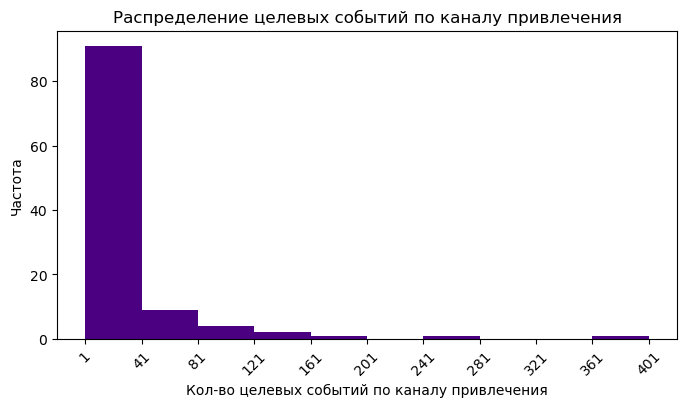

In [114]:
ga_tg_utm_source_piv_hist = ga_tg_utm_source_piv[
    (ga_tg_utm_source_piv.targeted <= 1000) & (ga_tg_utm_source_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_utm_source_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по каналу привлечения')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по каналу привлечения')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [115]:
ga_tg_utm_source_piv['utm_source_target_frequency'] = ga_tg_utm_source_piv.apply(
    lambda x: 'high' if x.targeted > 22 and x.targeted <= 100    
    else ('medium' if x.targeted > 11 and x.targeted <= 22
          else ('low' if x.targeted > 3 and x.targeted <= 11
                else ('too low' if x.targeted > 1 and x.targeted <= 3
                      else ('once' if x.targeted == 1
                            else ('zero' if x.targeted == 0
                                 else x.utm_source))))), axis=1)

In [116]:
ga_tg_utm_source_piv_dict =  ga_tg_utm_source_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_source_piv_dict, on=['utm_source'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 28)
(1732266, 29)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,visit_hour,uninformative_session,visit_month,visit_day,visit_week_day,device_app_category,organic_traffic,social_network,device_anomaly,utm_source_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,14,0,11,24,2,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,8,0,11,14,6,Browsers,0,1,0,MvfHsxITijuriZxsqZqt
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,2,0,12,28,1,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,5,0,5,29,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,5,0,5,29,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD


##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибута utm_medium</spam> 

In [117]:
ga_tg_utm_medium_piv = ga_tg.pivot_table(
    index=['utm_medium'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_utm_medium_piv = ga_tg_utm_medium_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_utm_medium_piv['perc_targeted'] = ga_tg_utm_medium_piv.targeted / (ga_tg_utm_medium_piv.targeted.sum()) * 100
ga_tg_utm_medium_piv = ga_tg_utm_medium_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_utm_medium_piv

event_session_target,utm_medium,not_targeted,targeted,perc_targeted
6,banner,510099.0,15107.0,30.025440
0,(none),266529.0,10531.0,20.930556
14,cpc,389866.0,9529.0,18.939063
41,referral,128670.0,8181.0,16.259888
15,cpm,227272.0,2519.0,5.006559
31,organic,52909.0,2100.0,4.173789
37,push,26870.0,840.0,1.669515
18,email,27886.0,401.0,0.796995
43,smartbanner,6322.0,179.0,0.355766
7,blogger_channel,7569.0,162.0,0.321978


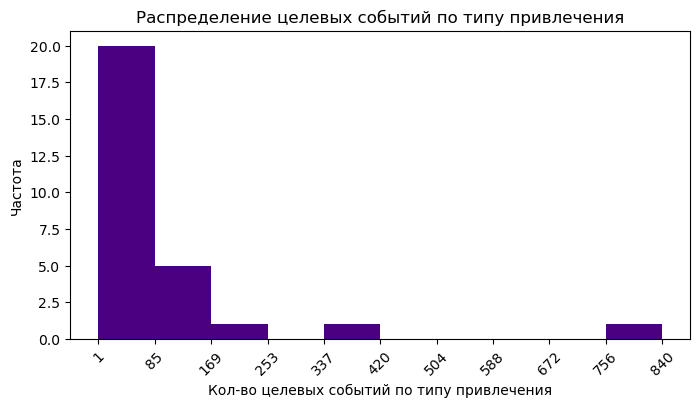

In [118]:
ga_tg_utm_medium_piv_hist = ga_tg_utm_medium_piv[
    (ga_tg_utm_medium_piv.targeted <= 2000) & (ga_tg_utm_medium_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_utm_medium_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по типу привлечения')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по типу привлечения')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [119]:
ga_tg_utm_medium_piv['utm_medium_target_frequency'] = ga_tg_utm_medium_piv.apply(
    lambda x: 'too low' if x.targeted > 1 and x.targeted <= 3
    else ('once' if x.targeted == 1
          else ('zero' if x.targeted == 0
               else x.utm_medium)), axis=1)

In [120]:
ga_tg_utm_medium_piv_dict =  ga_tg_utm_medium_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_medium_piv_dict, on=['utm_medium'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 29)
(1732266, 30)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,uninformative_session,visit_month,visit_day,visit_week_day,device_app_category,organic_traffic,social_network,device_anomaly,utm_source_target_frequency,utm_medium_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,11,24,2,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,0,11,14,6,Browsers,0,1,0,MvfHsxITijuriZxsqZqt,cpm
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,12,28,1,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,0,5,29,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,0,5,29,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc


##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибута utm_campaign</spam> 

In [121]:
ga_tg_utm_campaign_piv = ga_tg.pivot_table(
    index=['utm_campaign'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_utm_campaign_piv = ga_tg_utm_campaign_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_utm_campaign_piv['perc_targeted'] = ga_tg_utm_campaign_piv.targeted / (ga_tg_utm_campaign_piv.targeted.sum()) * 100
ga_tg_utm_campaign_piv = ga_tg_utm_campaign_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_utm_campaign_piv

event_session_target,utm_campaign,not_targeted,targeted,perc_targeted
87,LTuZkdKfxRGVceoWkVyg,404317.0,19077.0,37.915888
84,LEoPHuyFvzoNfnzGgfcd,311946.0,9350.0,18.583297
213,_none_,132365.0,4793.0,9.526176
256,gecBYcKZCPMcVYdSSzKP,128709.0,4546.0,9.035259
39,FTjNLDyTrXaWYgZymFkV,232514.0,2447.0,4.863457
...,...,...,...,...
205,YlsczTIyBSwTLNtuDkCd,1.0,0.0,0.000000
206,YpBKcihLLfFjWuxOLfvW,11.0,0.0,0.000000
207,YwbyBjVdPyyaRwqdjxpq,4.0,0.0,0.000000
208,ZHCJROlbqnkXTqIuVxnm,1.0,0.0,0.000000


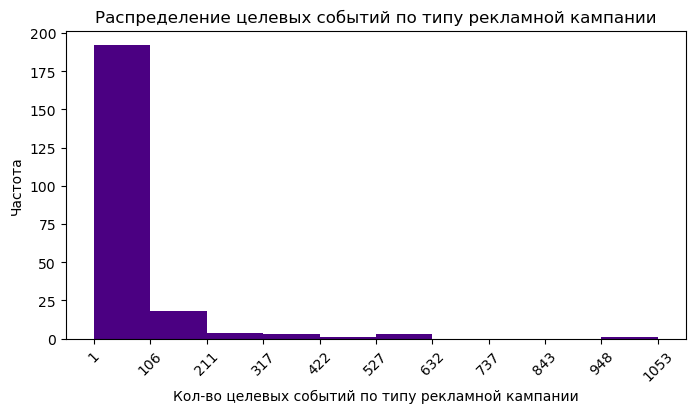

In [122]:
ga_tg_utm_campaign_piv_hist = ga_tg_utm_campaign_piv[
    (ga_tg_utm_campaign_piv.targeted <= 2000) & (ga_tg_utm_campaign_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_utm_campaign_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по типу рекламной кампании')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по типу рекламной кампании')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [123]:
ga_tg_utm_campaign_piv['utm_campaign_target_frequency'] = ga_tg_utm_campaign_piv.apply(
    lambda x: 'high' if x.targeted > 100 and x.targeted <= 170
    else ('medium' if x.targeted > 26 and x.targeted <= 100
          else ('medium to low' if x.targeted > 10 and x.targeted <= 26
                else ('low' if x.targeted > 3 and x.targeted <= 10
                      else ('too low' if x.targeted > 1 and x.targeted <= 3                                                                                                  
                            else ('once' if x.targeted == 1
                                  else ('zero' if x.targeted == 0
                                       else x.utm_campaign)))))), axis=1)		

In [124]:
ga_tg_utm_campaign_piv_dict =  ga_tg_utm_campaign_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_campaign_piv_dict, on=['utm_campaign'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 30)
(1732266, 31)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,visit_month,visit_day,visit_week_day,device_app_category,organic_traffic,social_network,device_anomaly,utm_source_target_frequency,utm_medium_target_frequency,utm_campaign_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,11,24,2,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,11,14,6,Browsers,0,1,0,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,12,28,1,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,5,29,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,5,29,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_


##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибута utm_adcontent</spam> 

In [125]:
ga_tg_utm_adcontent_piv = ga_tg.pivot_table(
    index=['utm_adcontent'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_utm_adcontent_piv = ga_tg_utm_adcontent_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_utm_adcontent_piv['perc_targeted'] = ga_tg_utm_adcontent_piv.targeted / (ga_tg_utm_adcontent_piv.targeted.sum()) * 100
ga_tg_utm_adcontent_piv = ga_tg_utm_adcontent_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_utm_adcontent_piv

event_session_target,utm_adcontent,not_targeted,targeted,perc_targeted
45,JNHcPlZPxEMWDnRiyoBf,1027533.0,37528.0,74.587590
140,_none_,166117.0,5073.0,10.082681
245,vCIpmpaGBnIQhyYNkXqp,175527.0,3911.0,7.773184
264,xhoenQgDQsgfEPYNPwKO,103113.0,1272.0,2.528123
82,PkybGvWbaqORmxjNunqZ,58065.0,978.0,1.943793
...,...,...,...,...
127,XcjjlqOiIMCDviWiXCQp,15.0,0.0,0.000000
129,YOrIewOuiNwUyeWViYQg,13.0,0.0,0.000000
130,YQdZdtbEmxfeXWbRMmXB,2.0,0.0,0.000000
132,YsLTNuzSAfbYGSpWDNpf,3.0,0.0,0.000000


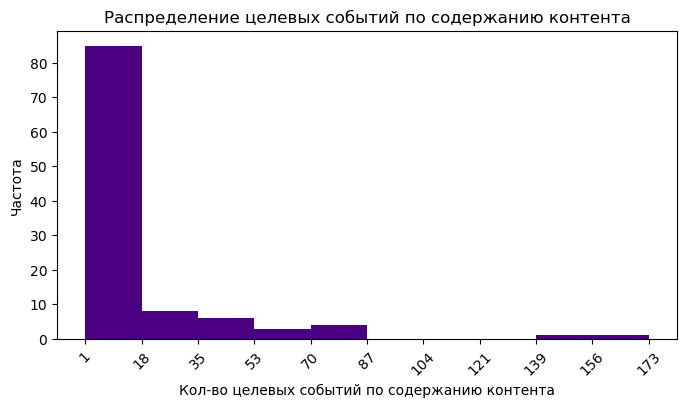

In [126]:
ga_tg_utm_adcontent_piv_hist = ga_tg_utm_adcontent_piv[
    (ga_tg_utm_adcontent_piv.targeted <= 900) & (ga_tg_utm_adcontent_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_utm_adcontent_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по содержанию контента')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по содержанию контента')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [127]:
ga_tg_utm_adcontent_piv['utm_adcontent_target_frequency'] = ga_tg_utm_adcontent_piv.apply(
    lambda x: 'medium' if x.targeted > 18 and x.targeted <= 100    
          else ('low' if x.targeted > 4 and x.targeted <= 18
                else ('too low' if x.targeted > 1 and x.targeted <= 4
                      else ('once' if x.targeted == 1
                            else ('zero' if x.targeted == 0
                                 else x.utm_adcontent)))), axis=1)

In [128]:
ga_tg_utm_adcontent_piv_dict =  ga_tg_utm_adcontent_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_adcontent_piv_dict, on=['utm_adcontent'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 31)
(1732266, 32)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,visit_day,visit_week_day,device_app_category,organic_traffic,social_network,device_anomaly,utm_source_target_frequency,utm_medium_target_frequency,utm_campaign_target_frequency,utm_adcontent_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,24,2,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,14,6,Browsers,0,1,0,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,28,1,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,29,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,29,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low


##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибута utm_keyword</spam> 

In [129]:
ga_tg_utm_keyword_piv = ga_tg.pivot_table(
    index='utm_keyword', columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_utm_keyword_piv = ga_tg_utm_keyword_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_utm_keyword_piv['perc_targeted'] = ga_tg_utm_keyword_piv.targeted / (ga_tg_utm_keyword_piv.targeted.sum()) * 100
ga_tg_utm_keyword_piv = ga_tg_utm_keyword_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_utm_keyword_piv

event_session_target,utm_keyword,not_targeted,targeted,perc_targeted
597,_none_,986169.0,34583.0,68.734348
958,puhZPIYqKXeFPaUviSjo,454765.0,11185.0,22.230393
748,hAmNSZmQkKQKAjZEGlgb,10073.0,349.0,0.693644
185,ITfrGJNwVsHBGJMAKoct,12073.0,322.0,0.639981
456,UKNBOHebRIIsQRsjNKay,9982.0,305.0,0.606193
...,...,...,...,...
485,VGDDruVvwprnUWMpndUF,1.0,0.0,0.000000
486,VQdCLycKmynJLXIDpEYt,45.0,0.0,0.000000
488,VZaORQTLxXvcGQnVAvjP,1.0,0.0,0.000000
489,VZxaKViwZIbyAQCieciI,2.0,0.0,0.000000


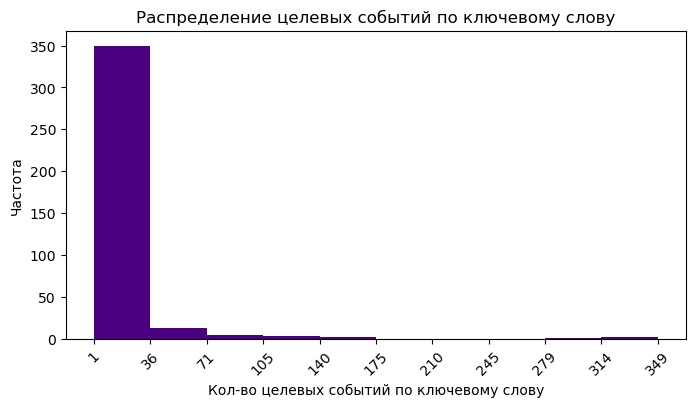

In [130]:
ga_tg_utm_keyword_piv_hist = ga_tg_utm_keyword_piv[
    (ga_tg_utm_keyword_piv.targeted <= 1000) & (ga_tg_utm_keyword_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_utm_keyword_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по ключевому слову')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по ключевому слову')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [131]:
ga_tg_utm_keyword_piv['utm_keyword_target_frequency'] = ga_tg_utm_keyword_piv.apply(lambda x: 'high' if x.targeted > 20 and x.targeted < 90
                                                                             else ('medium' if x.targeted > 9 and x.targeted <= 20
                                                                                   else ('low' if x.targeted > 3 and x.targeted <= 9
                                                                                        else ('too low' if x.targeted > 1 and x.targeted <= 3
                                                                                             else ('once' if x.targeted == 1
                                                                                                  else ('zero' if x.targeted == 0
                                                                                                       else x.utm_keyword))))), axis=1)

In [132]:
ga_tg_utm_keyword_piv_dict = ga_tg_utm_keyword_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_utm_keyword_piv_dict, on='utm_keyword', how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 32)
(1732266, 33)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,visit_week_day,device_app_category,organic_traffic,social_network,device_anomaly,utm_source_target_frequency,utm_medium_target_frequency,utm_campaign_target_frequency,utm_adcontent_target_frequency,utm_keyword_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,2,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,6,Browsers,0,1,0,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,1,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,5,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_


##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибута device_os</spam>

In [133]:
ga_tg_device_os_piv = ga_tg.pivot_table(
    index=['device_os'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_device_os_piv = ga_tg_device_os_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_device_os_piv['perc_targeted'] = ga_tg_device_os_piv.targeted / (ga_tg_device_os_piv.targeted.sum()) * 100
ga_tg_device_os_piv = ga_tg_device_os_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_device_os_piv

event_session_target,device_os,not_targeted,targeted,perc_targeted
1,Android,850243.0,24108.0,47.915093
13,iOS,489151.0,14468.0,28.755416
12,_none_,197839.0,7345.0,14.598323
10,Windows,90756.0,2160.0,4.293040
6,Macintosh,48864.0,2136.0,4.245339
5,Linux,4682.0,97.0,0.192789
0,(not set),309.0,0.0,0.000000
2,BlackBerry,24.0,0.0,0.000000
3,Chrome OS,68.0,0.0,0.000000
4,Firefox OS,3.0,0.0,0.000000


In [134]:
ga_tg_device_os_piv['device_os_target_frequency'] = ga_tg_device_os_piv.apply(
    lambda x: 'zero' if x.targeted == 0 else x.device_os, axis=1)

In [135]:
ga_tg_device_os_piv_dict =  ga_tg_device_os_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_device_os_piv_dict, on=['device_os'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 33)
(1732266, 34)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,device_app_category,organic_traffic,social_network,device_anomaly,utm_source_target_frequency,utm_medium_target_frequency,utm_campaign_target_frequency,utm_adcontent_target_frequency,utm_keyword_target_frequency,device_os_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,Browsers,0,1,0,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,Android
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Browsers,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,Browsers,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android


##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибута device_brand</spam>

In [136]:
ga_tg_device_brand_piv = ga_tg.pivot_table(
    index=['device_brand'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_device_brand_piv = ga_tg_device_brand_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_device_brand_piv['perc_targeted'] = ga_tg_device_brand_piv.targeted / (ga_tg_device_brand_piv.targeted.sum()) * 100
ga_tg_device_brand_piv = ga_tg_device_brand_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_device_brand_piv

event_session_target,device_brand,not_targeted,targeted,perc_targeted
10,Apple,537990.0,16604.0,33.000755
145,Samsung,301591.0,10054.0,19.982510
196,_none_,286740.0,9379.0,18.640935
191,Xiaomi,262667.0,6594.0,13.105696
76,Huawei,169309.0,4519.0,8.981596
...,...,...,...,...
92,Kingplay,15.0,0.0,0.000000
93,Komu,7.0,0.0,0.000000
94,Krip,2.0,0.0,0.000000
95,Kyocera,24.0,0.0,0.000000


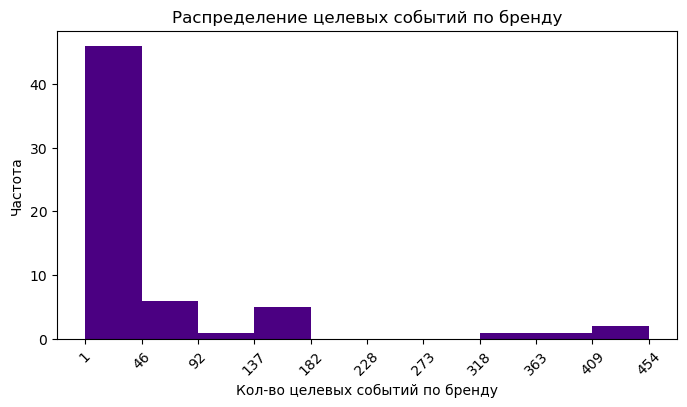

In [137]:
ga_tg_device_brand_piv_hist = ga_tg_device_brand_piv[
    (ga_tg_device_brand_piv.targeted <= 4000) & (ga_tg_device_brand_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_device_brand_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по бренду')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по бренду')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [138]:
ga_tg_device_brand_piv['device_brand_target_frequency'] = ga_tg_device_brand_piv.apply(
    lambda x: 'medium' if x.targeted > 7 and x.targeted <= 25
    else ('low' if x.targeted > 1 and x.targeted <= 7
          else ('once' if x.targeted == 1
                else ('zero' if x.targeted == 0
                      else x.device_brand))), axis=1)	

In [139]:
ga_tg_device_brand_piv_dict =  ga_tg_device_brand_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_device_brand_piv_dict, on=['device_brand'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 34)
(1732266, 35)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,organic_traffic,social_network,device_anomaly,utm_source_target_frequency,utm_medium_target_frequency,utm_campaign_target_frequency,utm_adcontent_target_frequency,utm_keyword_target_frequency,device_os_target_frequency,device_brand_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,0,1,0,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,Android,Samsung
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android,Xiaomi
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,0,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android,Xiaomi


##### <span style="color: brown;"> Анализ атрибута device_model</spam>

In [140]:
ga_tg.device_model.value_counts()

device_model
_none_                  1717204
AuMdmADEIoPXiWpTsBEj       9018
tWBQlsvNfHxRUjaPAfhd        596
cwMJxNXiWUgMUxGiCTPs        586
pTgAEPipQxDXCjPrJbHo        430
                         ...   
OJiWyBKOyDITzXCZRSMH          1
MBGYWAQSYWUphNxTsAWD          1
XnjPzKjkHmznVfULanbE          1
VDidzTqFGxuqiRQJGrwB          1
qmRODeCJLlmkmwxNYXvp          1
Name: count, Length: 105, dtype: int64

In [141]:
ga_tg[ga_tg.device_model!='_none_'].event_session_target.value_counts()[1] / ga_tg.event_session_target.sum()

np.float64(0.006797312875144095)

In [142]:
# Удаляем колонку device_model, т.к. много пропущенных значений и среди существующих маленькая конверсия

In [143]:
ga_tg = ga_tg.drop('device_model', axis=1)
print(ga_tg.shape)

(1732266, 34)


##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибута device_screen_resolution</spam> 

##### По категории desktop

In [144]:
ga_tg_device_screen_desc_piv = ga_tg[ga_tg.device_category=='desktop'].pivot_table(
    index=['device_category', 'device_screen_resolution'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_device_screen_desc_piv = ga_tg_device_screen_desc_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_device_screen_desc_piv['perc_targeted'] = ga_tg_device_screen_desc_piv.targeted / (ga_tg_device_screen_desc_piv.targeted.sum()) * 100
ga_tg_device_screen_desc_piv = ga_tg_device_screen_desc_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_device_screen_desc_piv

event_session_target,device_category,device_screen_resolution,not_targeted,targeted,perc_targeted
1049,desktop,1920x1080,115543.0,3576.0,31.060540
572,desktop,1440x900,28321.0,1400.0,12.160167
693,desktop,1536x864,34244.0,1238.0,10.753062
476,desktop,1366x768,30706.0,1089.0,9.458873
335,desktop,1280x720,18443.0,816.0,7.087640
...,...,...,...,...,...
587,desktop,1455x818,1.0,0.0,0.000000
586,desktop,1455x1091,1.0,0.0,0.000000
585,desktop,1451x907,1.0,0.0,0.000000
584,desktop,1451x816,6.0,0.0,0.000000


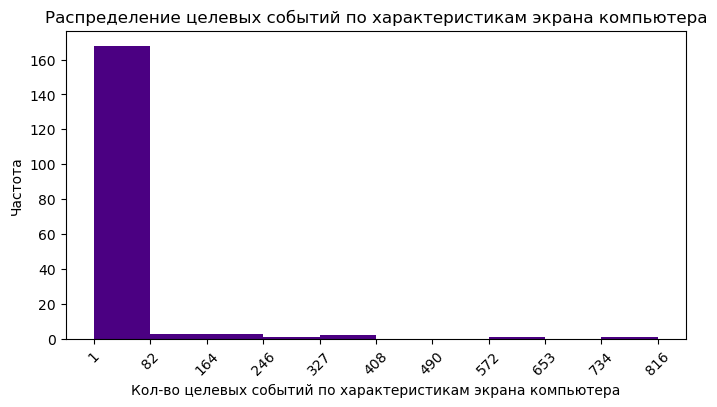

In [145]:
ga_tg_device_screen_desc_piv_hist = ga_tg_device_screen_desc_piv[
    (ga_tg_device_screen_desc_piv.targeted <= 1000) & (ga_tg_device_screen_desc_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_device_screen_desc_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по характеристикам экрана компьютера')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по характеристикам экрана компьютера')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [146]:
ga_tg_device_screen_desc_piv['device_screen_target_frequency'] = ga_tg_device_screen_desc_piv.apply(
    lambda x: 'desktop - high' if x.targeted > 90 and x.targeted <= 600
    else ('desktop - medium' if x.targeted > 15 and x.targeted <= 90 
          else ('desktop - medium to low' if x.targeted > 8 and x.targeted <= 15
                else ('desktop - low' if x.targeted > 3 and x.targeted <= 8
                      else ('desktop - too low' if x.targeted > 1 and x.targeted <= 3                                                                                                    
                            else ('desktop - once' if x.targeted == 1
                                  else ('desktop - zero' if x.targeted == 0
                                       else x.device_category + ' ' + x.device_screen_resolution)))))), axis=1)

In [147]:
ga_tg_device_screen_desc_piv_dict = ga_tg_device_screen_desc_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])

##### По категории mobile

In [148]:
ga_tg_device_screen_mobile_piv = ga_tg[ga_tg.device_category=='mobile'].pivot_table(
    index=['device_category', 'device_screen_resolution'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_device_screen_mobile_piv = ga_tg_device_screen_mobile_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_device_screen_mobile_piv['perc_targeted'] = ga_tg_device_screen_mobile_piv.targeted / (ga_tg_device_screen_mobile_piv.targeted.sum()) * 100
ga_tg_device_screen_mobile_piv = ga_tg_device_screen_mobile_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_device_screen_mobile_piv

event_session_target,device_category,device_screen_resolution,not_targeted,targeted,perc_targeted
1940,mobile,414x896,150404.0,4373.0,11.394252
889,mobile,375x812,103533.0,3156.0,8.223247
1301,mobile,393x851,104254.0,2907.0,7.574455
1795,mobile,412x915,67790.0,2667.0,6.949113
840,mobile,375x667,82674.0,2442.0,6.362855
...,...,...,...,...,...
1167,mobile,393x1014,1.0,0.0,0.000000
1168,mobile,393x1018,1.0,0.0,0.000000
1169,mobile,393x1020,2.0,0.0,0.000000
1170,mobile,393x1021,1.0,0.0,0.000000


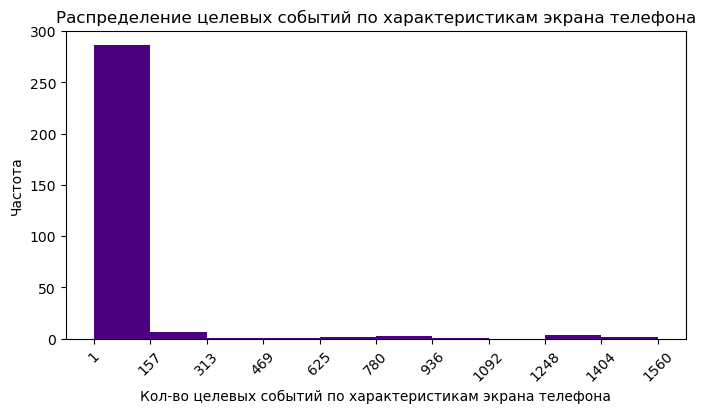

In [149]:
ga_tg_device_screen_mobile_piv_hist = ga_tg_device_screen_mobile_piv[
    (ga_tg_device_screen_mobile_piv.targeted <= 2000) & (ga_tg_device_screen_mobile_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_device_screen_mobile_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по характеристикам экрана телефона')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по характеристикам экрана телефона')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [150]:
ga_tg_device_screen_mobile_piv['device_screen_target_frequency'] = ga_tg_device_screen_mobile_piv.apply(
    lambda x: 'mobile - high' if x.targeted > 150 and x.targeted <= 600
    else ('mobile - medium' if x.targeted > 26 and x.targeted <= 150
          else ('mobile - medium to low' if x.targeted > 11 and x.targeted <= 26
                else ('mobile - low' if x.targeted > 6 and x.targeted <= 11
                      else ('mobile - too low' if x.targeted > 1 and x.targeted <= 6                                                                                                   
                            else ('mobile - once' if x.targeted == 1
                                  else ('mobile - zero' if x.targeted == 0
                                       else x.device_category + ' ' + x.device_screen_resolution)))))), axis=1)

In [151]:
ga_tg_device_screen_mobile_piv_dict =  ga_tg_device_screen_mobile_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])

##### По категории tablet

In [152]:
ga_tg_device_screen_tablet_piv = ga_tg[ga_tg.device_category=='tablet'].pivot_table(
    index=['device_category', 'device_screen_resolution'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_device_screen_tablet_piv = ga_tg_device_screen_tablet_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_device_screen_tablet_piv['perc_targeted'] = ga_tg_device_screen_tablet_piv.targeted / (ga_tg_device_screen_tablet_piv.targeted.sum()) * 100
ga_tg_device_screen_tablet_piv = ga_tg_device_screen_tablet_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_device_screen_tablet_piv

event_session_target,device_category,device_screen_resolution,not_targeted,targeted,perc_targeted
281,tablet,768x1024,3488.0,85.0,20.142180
208,tablet,601x962,946.0,38.0,9.004739
56,tablet,1280x800,1110.0,30.0,7.109005
179,tablet,534x854,876.0,25.0,5.924171
287,tablet,800x1280,879.0,23.0,5.450237
...,...,...,...,...,...
131,tablet,397x678,1.0,0.0,0.000000
130,tablet,393x873,2.0,0.0,0.000000
129,tablet,393x851,13.0,0.0,0.000000
128,tablet,393x822,1.0,0.0,0.000000


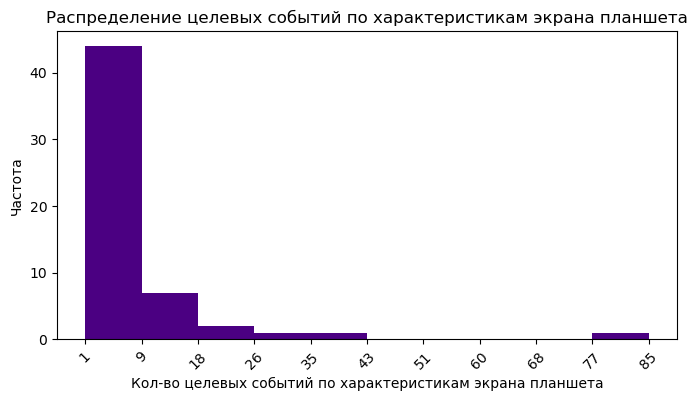

In [153]:
ga_tg_device_screen_tablet_piv_hist = ga_tg_device_screen_tablet_piv[
    (ga_tg_device_screen_tablet_piv.targeted <= 800) & (ga_tg_device_screen_tablet_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_device_screen_tablet_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по характеристикам экрана планшета')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по характеристикам экрана планшета')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [154]:
ga_tg_device_screen_tablet_piv['device_screen_target_frequency'] = ga_tg_device_screen_tablet_piv.apply(
    lambda x: 'tablet - medium' if x.targeted > 6 and x.targeted <= 20
    else ('tablet - low' if x.targeted > 3 and x.targeted <= 6
           else ('tablet - too low' if x.targeted > 1 and x.targeted <= 3                                                                                                
                  else ('tablet - once' if x.targeted == 1
                        else ('tablet - zero' if x.targeted == 0
                             else x.device_category + ' ' + x.device_screen_resolution)))), axis=1)

In [155]:
ga_tg_device_screen_tablet_piv_dict =  ga_tg_device_screen_tablet_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])

In [156]:
# Объединение словарей в один и добавление новой колонки

ga_tg_device_screen_piv_dict = pd.concat([ga_tg_device_screen_desc_piv_dict, 
                                          ga_tg_device_screen_mobile_piv_dict, 
                                          ga_tg_device_screen_tablet_piv_dict], axis=0, ignore_index=True)
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_device_screen_piv_dict, on=['device_category', 'device_screen_resolution'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 34)
(1732266, 35)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,social_network,device_anomaly,utm_source_target_frequency,utm_medium_target_frequency,utm_campaign_target_frequency,utm_adcontent_target_frequency,utm_keyword_target_frequency,device_os_target_frequency,device_brand_target_frequency,device_screen_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei,mobile 360x720
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,1,0,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,Android,Samsung,mobile 385x854
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei,mobile 360x720
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android,Xiaomi,mobile - high
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,0,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android,Xiaomi,mobile - high


##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибута device_browser</spam> 

In [157]:
ga_tg_device_browser_piv = ga_tg.pivot_table(
    index=['device_browser'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_device_browser_piv = ga_tg_device_browser_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_device_browser_piv['perc_targeted'] = ga_tg_device_browser_piv.targeted / (ga_tg_device_browser_piv.targeted.sum()) * 100
ga_tg_device_browser_piv = ga_tg_device_browser_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_device_browser_piv

event_session_target,device_browser,not_targeted,targeted,perc_targeted
6,Chrome,924385.0,27188.0,54.036650
44,Safari,423382.0,13323.0,26.479707
50,YaBrowser,119679.0,4086.0,8.121000
5,Android Webview,50364.0,1555.0,3.090591
46,Samsung Internet,43016.0,1257.0,2.498311
45,Safari (in-app),64731.0,1221.0,2.426760
9,Firefox,15160.0,578.0,1.148786
41,Opera,24533.0,561.0,1.114998
8,Edge,14670.0,526.0,1.045435
49,UC Browser,801.0,14.0,0.027825


In [158]:
ga_tg_device_browser_piv['device_browser_target_frequency'] = ga_tg_device_browser_piv.apply(
    lambda x: 'too low' if x.targeted >= 1 and x.targeted < 14
                            else ('zero' if x.targeted == 0
                                 else x.device_browser), axis=1)

In [159]:
ga_tg_device_browser_piv_dict =  ga_tg_device_browser_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_device_browser_piv_dict, on=['device_browser'], how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 35)
(1732266, 36)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,device_anomaly,utm_source_target_frequency,utm_medium_target_frequency,utm_campaign_target_frequency,utm_adcontent_target_frequency,utm_keyword_target_frequency,device_os_target_frequency,device_brand_target_frequency,device_screen_target_frequency,device_browser_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei,mobile 360x720,Chrome
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,0,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,Android,Samsung,mobile 385x854,Samsung Internet
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei,mobile 360x720,Chrome
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android,Xiaomi,mobile - high,Chrome
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,0,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android,Xiaomi,mobile - high,Chrome


##### <span style="color: brown;"> Создание атрибута со сгруппированными по целевому событию значениями для атрибутов geo_country и geo_city</spam> 

In [160]:
# Создание вспомогательного атрибута geo

ga_tg['geo'] = ga_tg.apply(lambda x: x.geo_country + ' - ' + x.geo_city, axis=1)

In [161]:
ga_tg_geo_piv = ga_tg.pivot_table(
    index=['geo'], columns='event_session_target', values='session_id', aggfunc='count').fillna(0)
ga_tg_geo_piv = ga_tg_geo_piv.rename(columns={1: 'targeted', 0: 'not_targeted'})
ga_tg_geo_piv['perc_targeted'] = ga_tg_geo_piv.targeted / (ga_tg_geo_piv.targeted.sum()) * 100
ga_tg_geo_piv = ga_tg_geo_piv.reset_index().sort_values('perc_targeted', ascending=False)
ga_tg_geo_piv

event_session_target,geo,not_targeted,targeted,perc_targeted
1385,Russia - Moscow,727299.0,23629.0,46.963072
1488,Russia - Saint Petersburg,271289.0,7113.0,14.137218
1138,Russia - (not set),64394.0,1361.0,2.705013
1285,Russia - Kazan,26550.0,1139.0,2.263783
1326,Russia - Krasnodar,29179.0,1081.0,2.148507
...,...,...,...,...
917,Malaysia - Ampang Jaya,1.0,0.0,0.000000
916,Malaysia - (not set),1.0,0.0,0.000000
915,Madagascar - Antananarivo,2.0,0.0,0.000000
914,Luxembourg - Strassen,1.0,0.0,0.000000


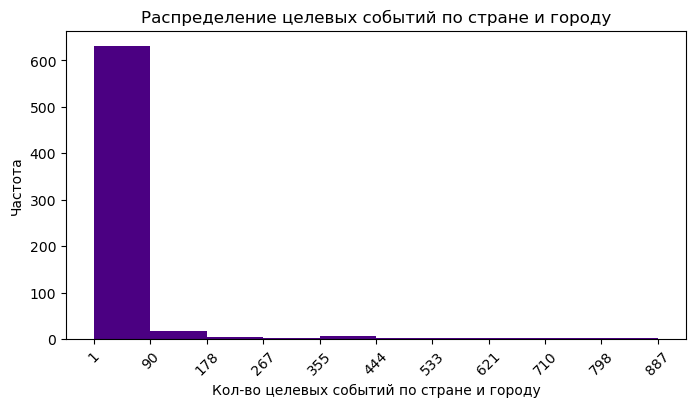

In [162]:
ga_tg_geo_piv_hist = ga_tg_geo_piv[(ga_tg_geo_piv.targeted <=1000) & (ga_tg_geo_piv.targeted > 0)]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_geo_piv_hist.targeted, bins=10, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Кол-во целевых событий по стране и городу')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по стране и городу')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

In [163]:
ga_tg_geo_piv['geo_target_frequency'] = ga_tg_geo_piv.apply(lambda x: 'high' if x.targeted > 73 and x.targeted < 200
                                                                             else ('medium' if x.targeted > 37 and x.targeted <= 73
                                                                                   else ('medium to low' if x.targeted > 9 and x.targeted <= 37
                                                                                        else ('low' if x.targeted > 3 and x.targeted <= 9
                                                                                              else ('too low' if x.targeted > 1 and x.targeted <= 3                                                                                                    
                                                                                                    else ('once' if x.targeted == 1
                                                                                                          else ('zero' if x.targeted == 0
                                                                                                               else x.geo)))))), axis=1)

In [164]:
ga_tg_geo_piv_dict = ga_tg_geo_piv.drop(columns=['not_targeted', 'targeted', 'perc_targeted'])
print(ga_tg.shape)
ga_tg = pd.merge(left=ga_tg, right=ga_tg_geo_piv_dict, on='geo', how='left')
print(ga_tg.shape)
ga_tg.head()

(1732266, 37)
(1732266, 38)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,utm_medium_target_frequency,utm_campaign_target_frequency,utm_adcontent_target_frequency,utm_keyword_target_frequency,device_os_target_frequency,device_brand_target_frequency,device_screen_target_frequency,device_browser_target_frequency,geo,geo_target_frequency
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei,mobile 360x720,Chrome,Russia - Zlatoust,too low
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,Android,Samsung,mobile 385x854,Samsung Internet,Russia - Moscow,Russia - Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei,mobile 360x720,Chrome,Russia - Krasnoyarsk,Russia - Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,cpc,_none_,low,_none_,Android,Xiaomi,mobile - high,Chrome,Russia - Moscow,Russia - Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,_none_,NOBKLgtuvqYWkXQHeYWM,_none_,...,cpc,_none_,low,_none_,Android,Xiaomi,mobile - high,Chrome,Russia - Moscow,Russia - Moscow


In [165]:
ga_tg = ga_tg.drop('geo', axis=1)

In [166]:
ga_tg.columns

Index(['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number',
       'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent',
       'utm_keyword', 'device_category', 'device_os', 'device_brand',
       'device_screen_resolution', 'device_browser', 'geo_country', 'geo_city',
       'event_session_target', 'visit_hour', 'uninformative_session',
       'visit_month', 'visit_day', 'visit_week_day', 'device_app_category',
       'organic_traffic', 'social_network', 'device_anomaly',
       'utm_source_target_frequency', 'utm_medium_target_frequency',
       'utm_campaign_target_frequency', 'utm_adcontent_target_frequency',
       'utm_keyword_target_frequency', 'device_os_target_frequency',
       'device_brand_target_frequency', 'device_screen_target_frequency',
       'device_browser_target_frequency', 'geo_target_frequency'],
      dtype='object')

In [167]:
#ga_tg.to_csv('final_work_feature_eng.csv', index=False)

## Data analyzing

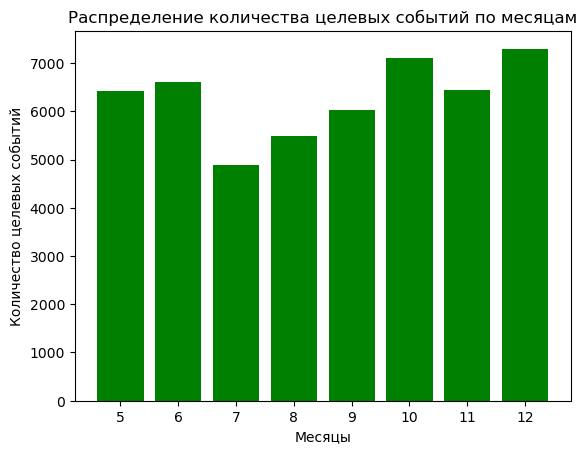

In [168]:
ga_tg_hist = ga_tg.groupby(['visit_month'], as_index=False).agg(count_target = ('event_session_target','sum'))

plt.bar(ga_tg_hist.visit_month, ga_tg_hist.count_target, color=['green'])
plt.xlabel('Месяцы')
plt.ylabel('Количество целевых событий')
plt.title('Распределение количества целевых событий по месяцам');

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

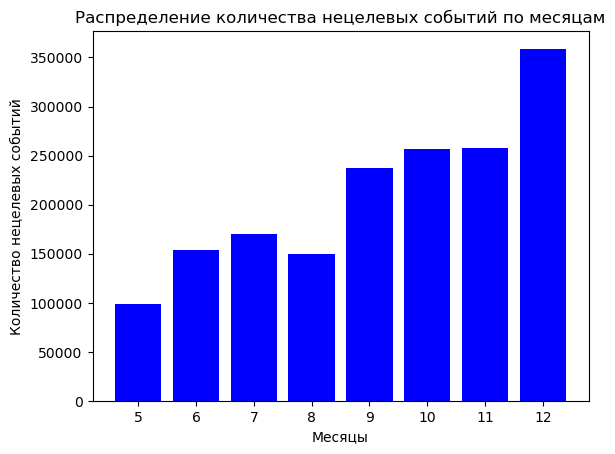

In [169]:
ga_tg_hist = ga_tg[ga_tg.event_session_target==0].groupby(['visit_month'], as_index=False).agg(count_target = ('event_session_target','count'))

plt.bar(ga_tg_hist.visit_month, ga_tg_hist.count_target, color=['blue'])
plt.xlabel('Месяцы')
plt.ylabel('Количество нецелевых событий')
plt.title('Распределение количества нецелевых событий по месяцам');

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

Распределение целевых событий в течение всего периода равномерное, в декабре чуть больше, а у нецелевых пик активности приходится на декабрь, причем с каждым месяцем активность возрастает. Пользователи интересуются предложенными услугами на сайте, но целевое действие не совершают.  

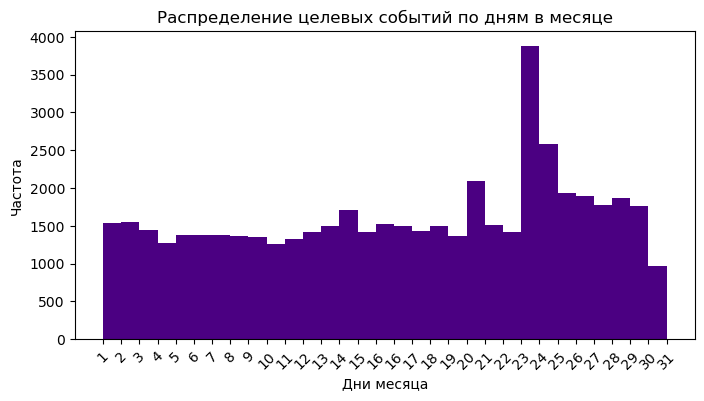

In [170]:
ga_tg_hist = ga_tg[ga_tg.event_session_target==1]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_hist.visit_day, bins=31, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Дни месяца')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по дням в месяце')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

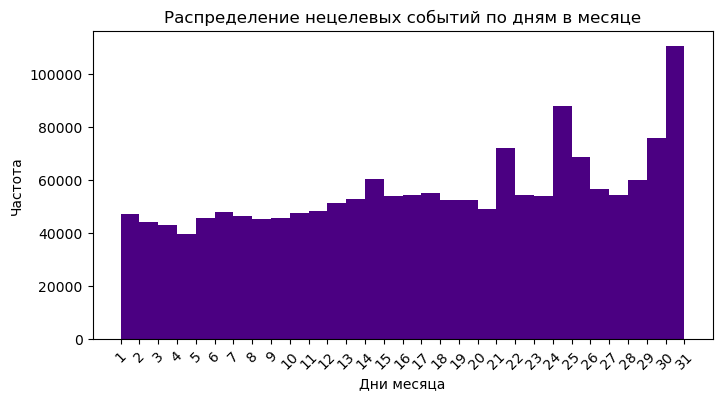

In [171]:
ga_tg_hist = ga_tg[ga_tg.event_session_target==0]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_hist.visit_day, bins=30, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Дни месяца')
ax.set_ylabel('Частота')
ax.set_title('Распределение нецелевых событий по дням в месяце')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

Здесь ситуация похожая в обоих случаях, всплеск целевых и нецелевых событий приходится на конец месяца, а целевых 24 числа.

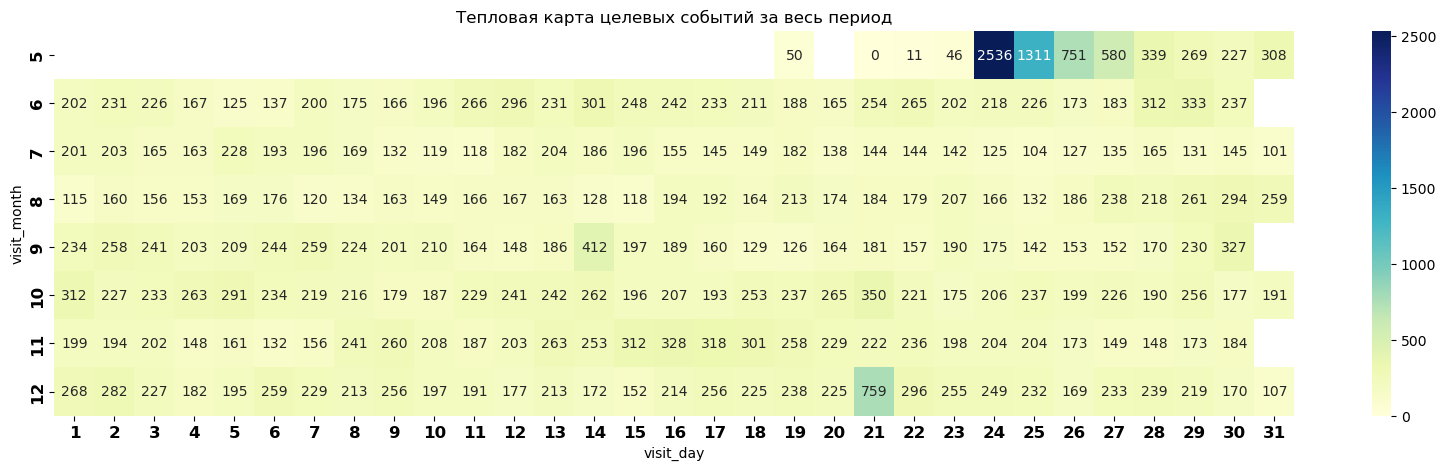

In [172]:
ga_tg_piv_visits = ga_tg.pivot_table(index='visit_month', columns='visit_day', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(20,5))
plt.title('Тепловая карта целевых событий за весь период')
sns.heatmap(data=ga_tg_piv_visits,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

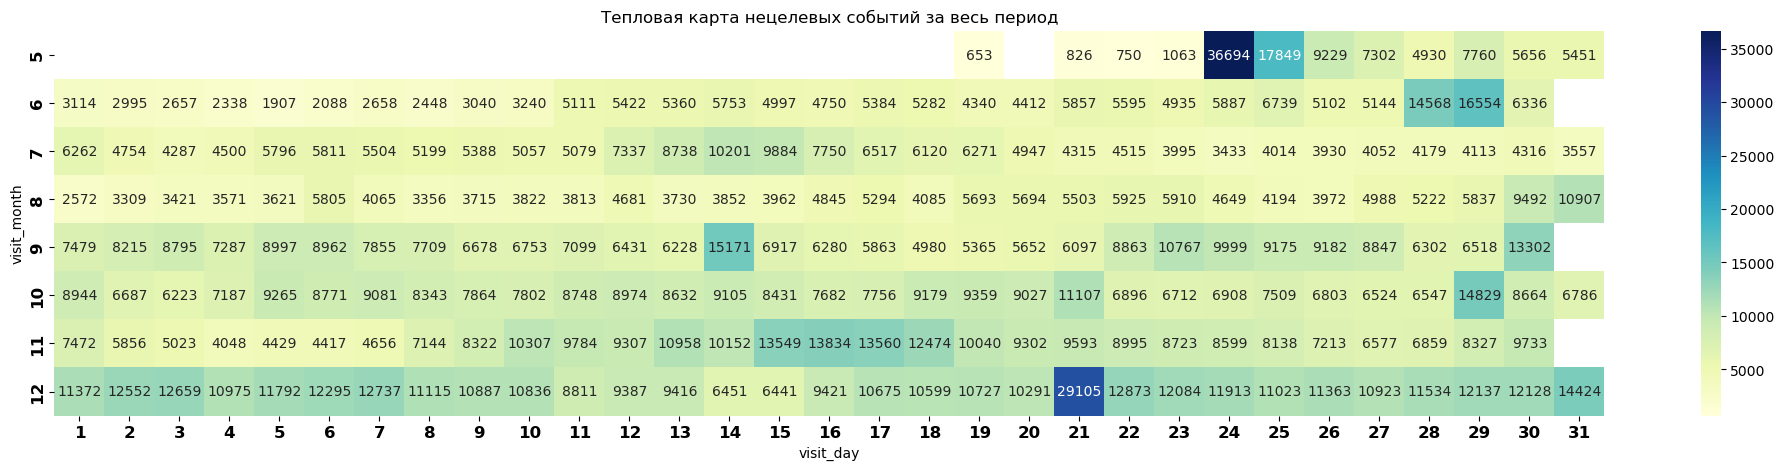

In [173]:
ga_tg_piv_visits = ga_tg[ga_tg.event_session_target==0].pivot_table(
    index='visit_month', columns='visit_day', values='event_session_target', aggfunc='count')

plt.figure(figsize=(25,5))
plt.title('Тепловая карта нецелевых событий за весь период')
sns.heatmap(data=ga_tg_piv_visits,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

На тепловых картах мы также видим равномерность целевых и неравномерность нецелевых событий за весь период, а также дни целевой и нецелевой активности. Особенно привлекают внимание дни максимальных всплесков событий 24.05, 25.05 и 21.12. 

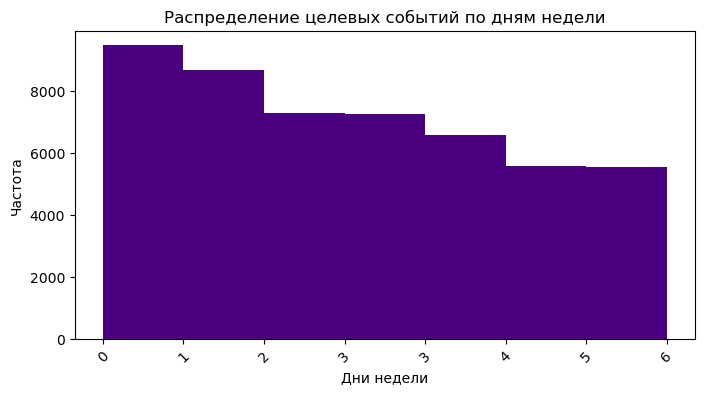

In [174]:
ga_tg_hist = ga_tg[ga_tg.event_session_target==1]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_hist.visit_week_day, bins=7, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Дни недели')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий по дням недели')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

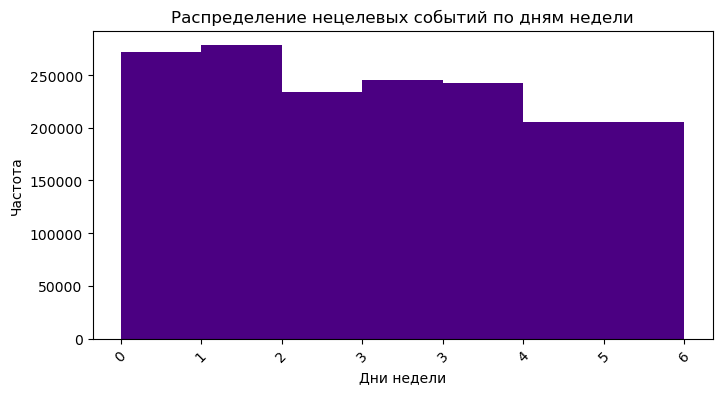

In [175]:
ga_tg_hist = ga_tg[ga_tg.event_session_target==0]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_hist.visit_week_day, bins=7, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Дни недели')
ax.set_ylabel('Частота')
ax.set_title('Распределение нецелевых событий по дням недели')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

Целевые и нецелевые события в большем количестве совершаются в начале недели.

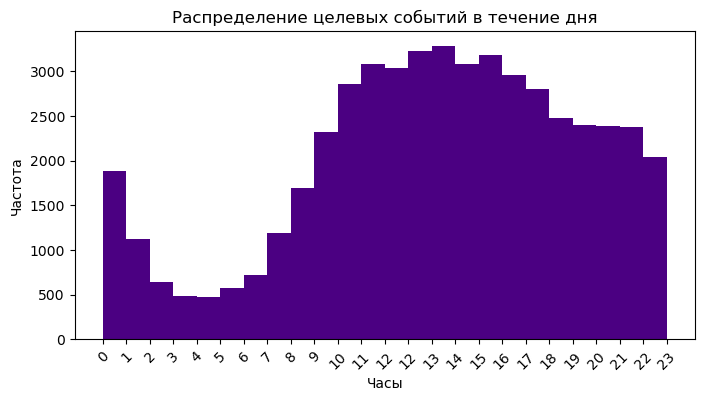

In [176]:
ga_tg_hist = ga_tg[ga_tg.event_session_target==1]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_hist.visit_hour, bins=24, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Часы')
ax.set_ylabel('Частота')
ax.set_title('Распределение целевых событий в течение дня')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

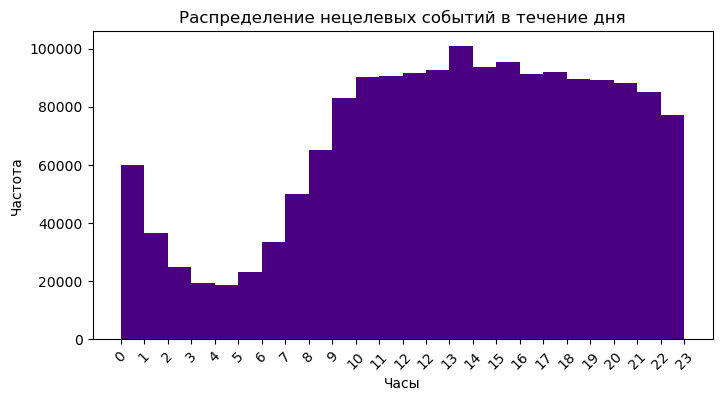

In [177]:
ga_tg_hist = ga_tg[ga_tg.event_session_target==0]

fig, ax = plt.subplots(figsize=(8, 4))
counts, bins, patches = ax.hist(ga_tg_hist.visit_hour, bins=24, color='indigo')
plt.xticks(bins, rotation=45)
ax.set_xlabel('Часы')
ax.set_ylabel('Частота')
ax.set_title('Распределение нецелевых событий в течение дня')

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

Здесь максимальная активность в обоих случаях с утра и до ночи.

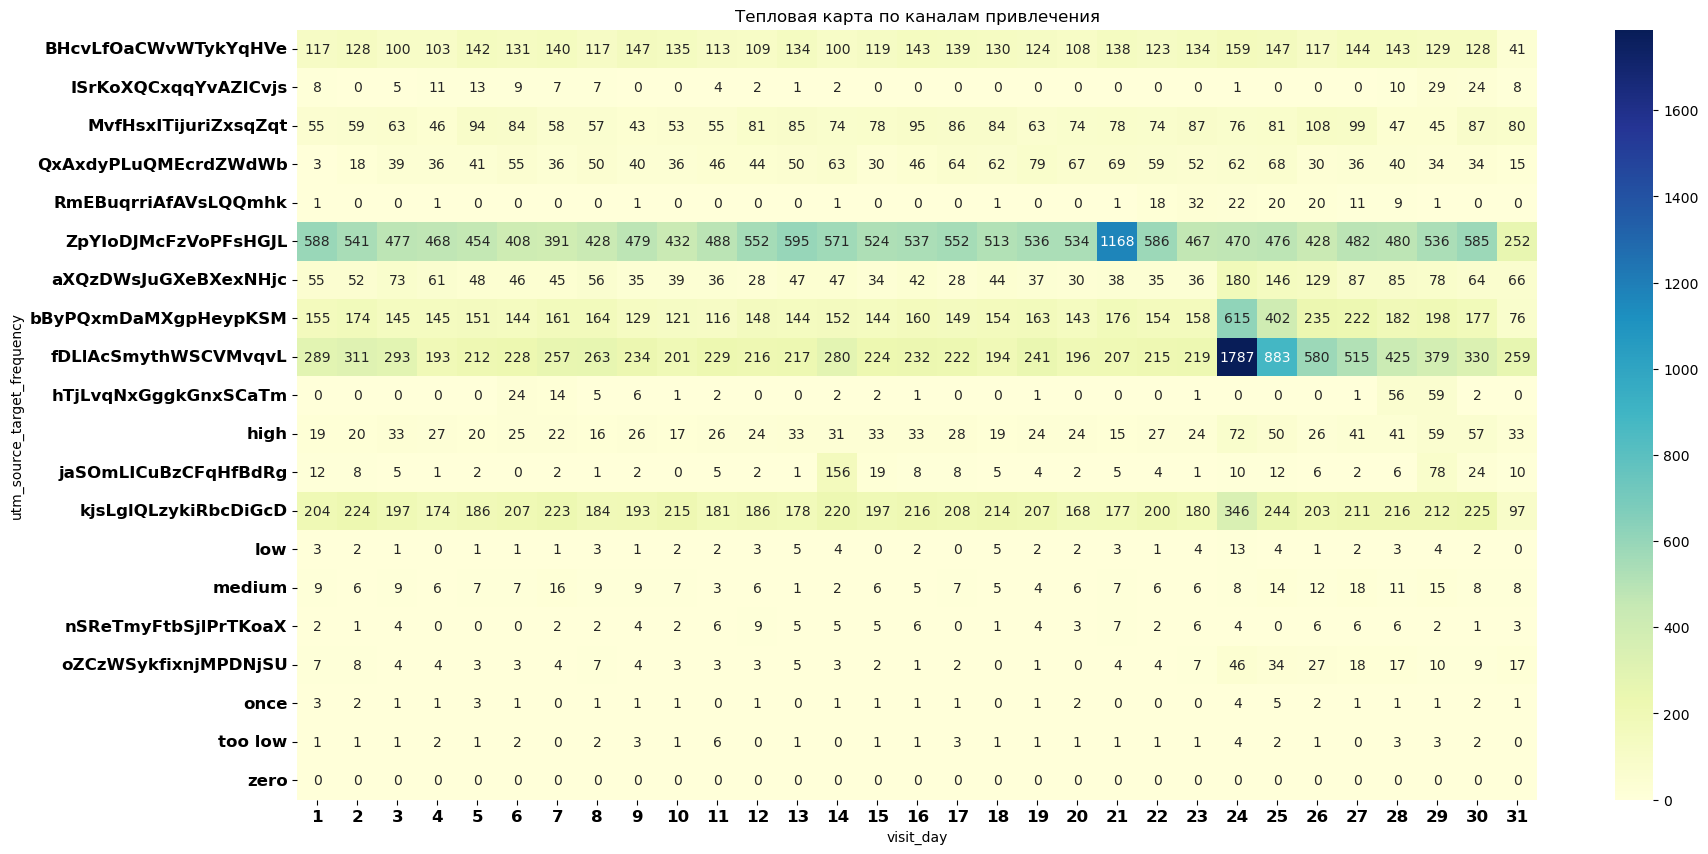

In [178]:
ga_tg_piv_utm_source = ga_tg.pivot_table(
    index='utm_source_target_frequency', columns='visit_day', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(20,10))
plt.title('Тепловая карта по каналам привлечения')
sns.heatmap(data=ga_tg_piv_utm_source,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

Выделены самые популярные каналы и указанные выше дни целевой активности.

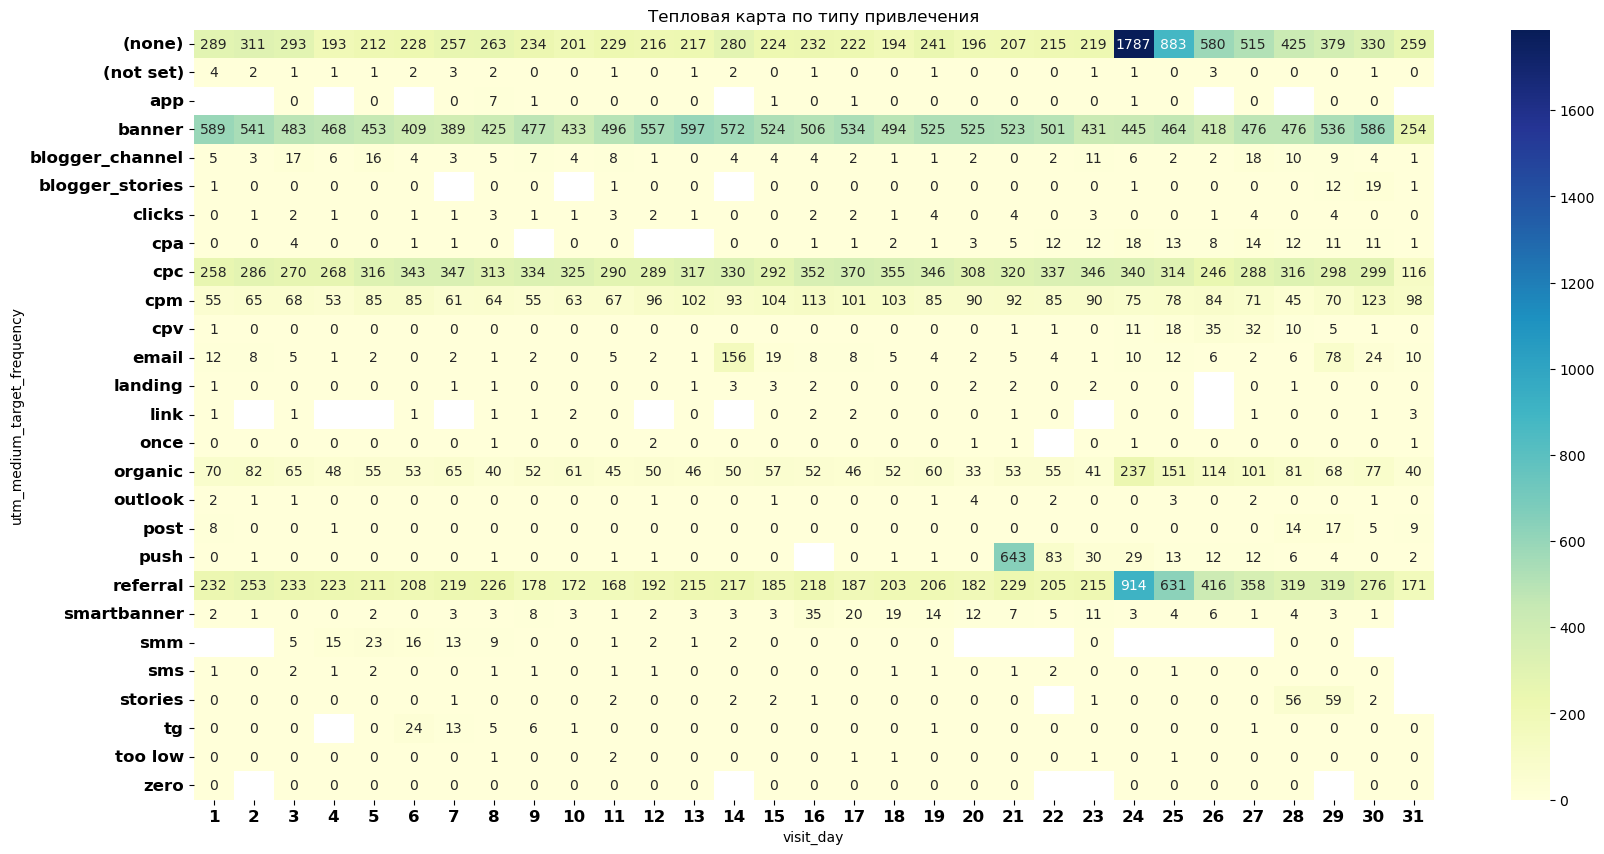

In [179]:
ga_tg_piv_utm_medium = ga_tg.pivot_table(index='utm_medium_target_frequency', columns='visit_day', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(20,10))
plt.title('Тепловая карта по типу привлечения')
sns.heatmap(data=ga_tg_piv_utm_medium,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

Типы привлечения banner, (none), cpc и referral самые популярные, активность у banner и cpc распределена равномерно по всем дням месяца, кроме последнего, а у (none) и referral целевая активность как раз происходила 24 и 25 числа, удивительная целевая активность выражена у непопулярного типа привлечения push 21 числа.

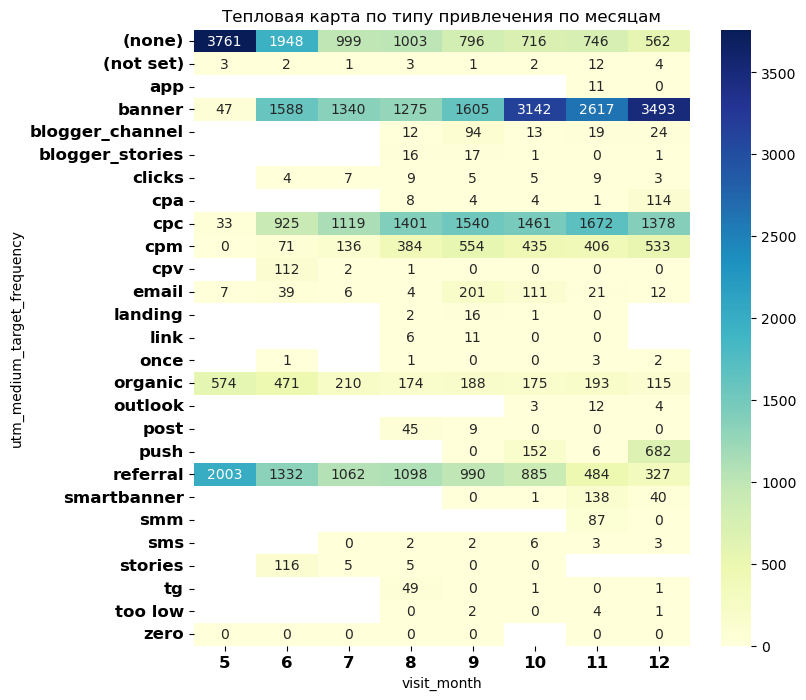

In [180]:
ga_tg_piv_utm_campaign = ga_tg.pivot_table(
    index='utm_medium_target_frequency', columns='visit_month', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(8,8))
plt.title('Тепловая карта по типу привлечения по месяцам')
sns.heatmap(data=ga_tg_piv_utm_campaign,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

Самый популярный трафик (тип привлечения) практически весь органический, а также неорганический cpc и banner. Причем у органического трафика активность целевых событий снижается с каждым месяцем, а у неорганического трафика наоборот повышается.

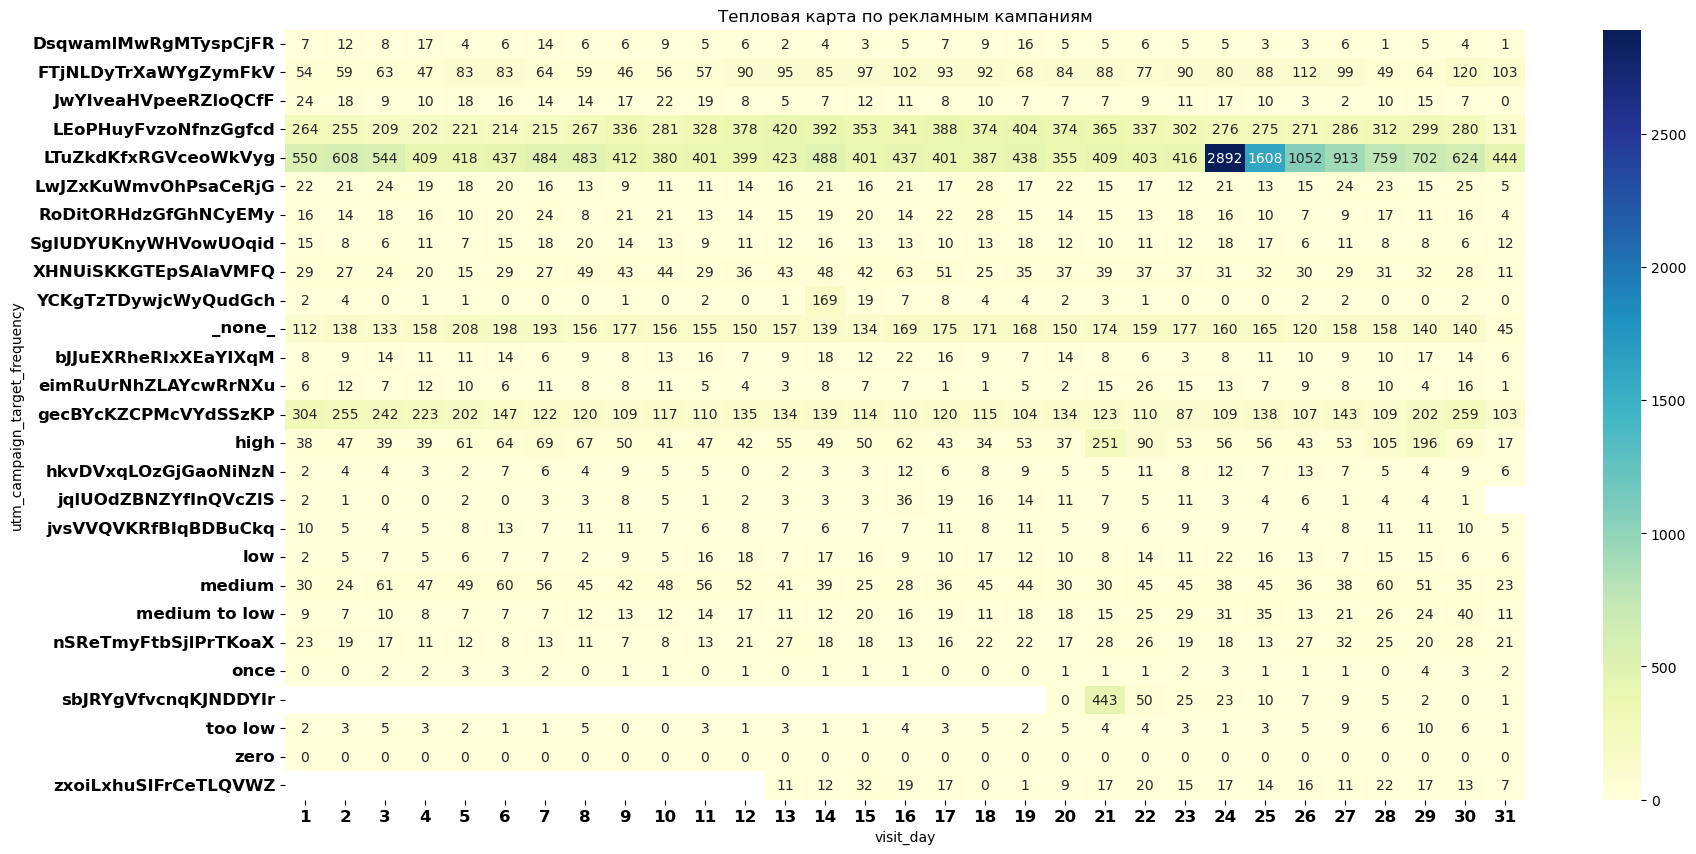

In [181]:
ga_tg_piv_utm_campaign = ga_tg.pivot_table(
    index='utm_campaign_target_frequency', columns='visit_day', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(20,10))
plt.title('Тепловая карта по рекламным кампаниям')
sns.heatmap(data=ga_tg_piv_utm_campaign,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

Здесь также выражена активность 24 числа.

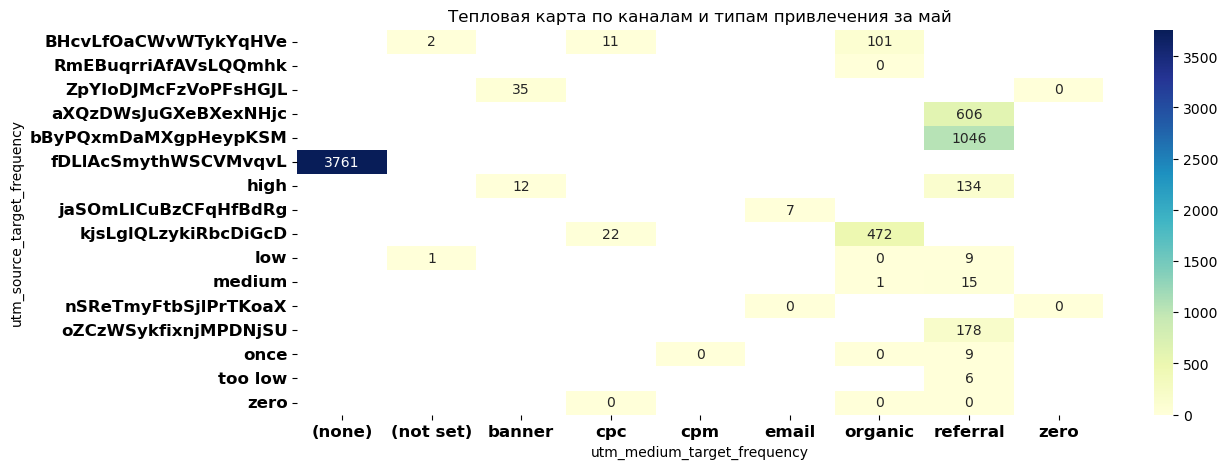

In [182]:
ga_tg_piv_source_medium = ga_tg[ga_tg.visit_month==5].pivot_table(index='utm_source_target_frequency', columns='utm_medium_target_frequency', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(13,5))
plt.title('Тепловая карта по каналам и типам привлечения за май')
sns.heatmap(data=ga_tg_piv_source_medium,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

В мае тесная связь образована между каналом привлечения fDLlAcSmythWSCVMvqvL и типом привлечения (none).

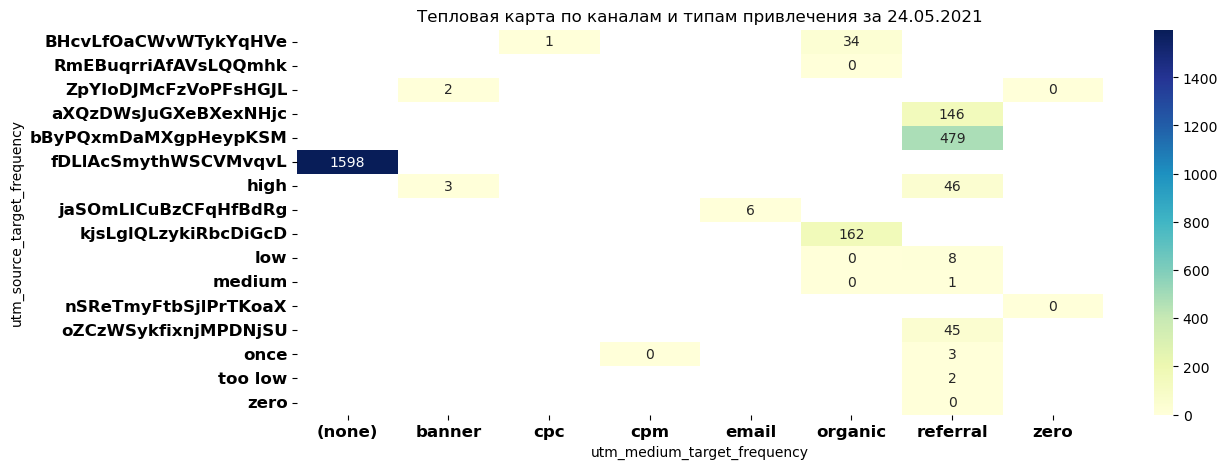

In [183]:
ga_tg_piv_source_medium = ga_tg[ga_tg.visit_date=='2021-05-24'].pivot_table(index='utm_source_target_frequency', columns='utm_medium_target_frequency', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(13,5))
plt.title('Тепловая карта по каналам и типам привлечения за 24.05.2021')
sns.heatmap(data=ga_tg_piv_source_medium,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

В день 24.05 видна та же связь.

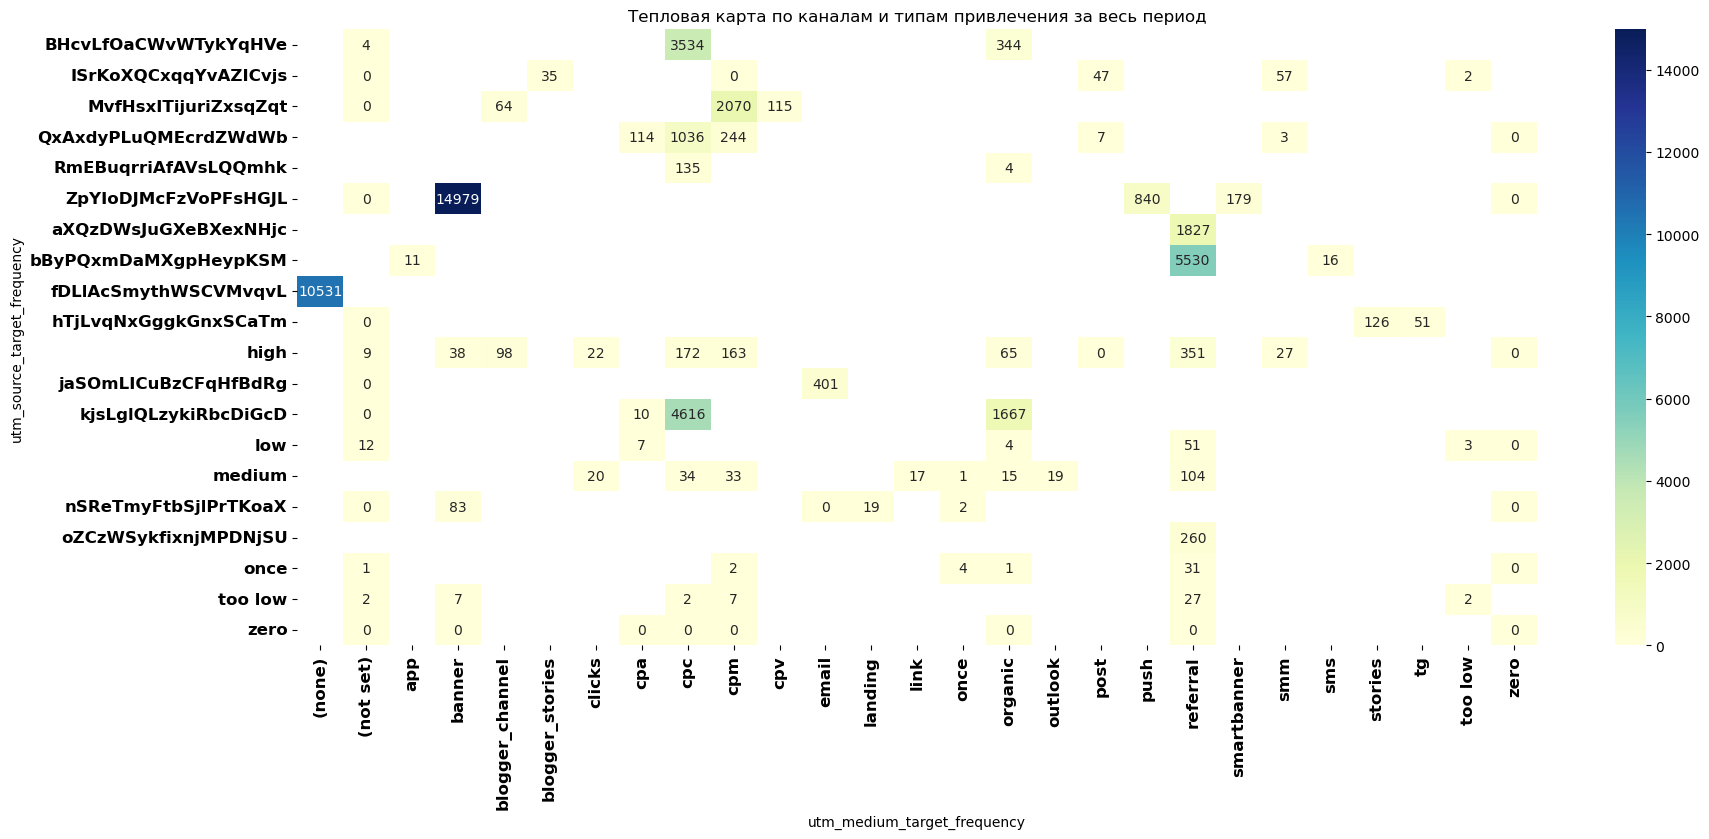

In [184]:
ga_tg_piv_source_medium = ga_tg.pivot_table(index='utm_source_target_frequency', columns='utm_medium_target_frequency', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(20,8))
plt.title('Тепловая карта по каналам и типам привлечения за весь период')
sns.heatmap(data=ga_tg_piv_source_medium,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

За весь период та же тесная связь наблюдается. 

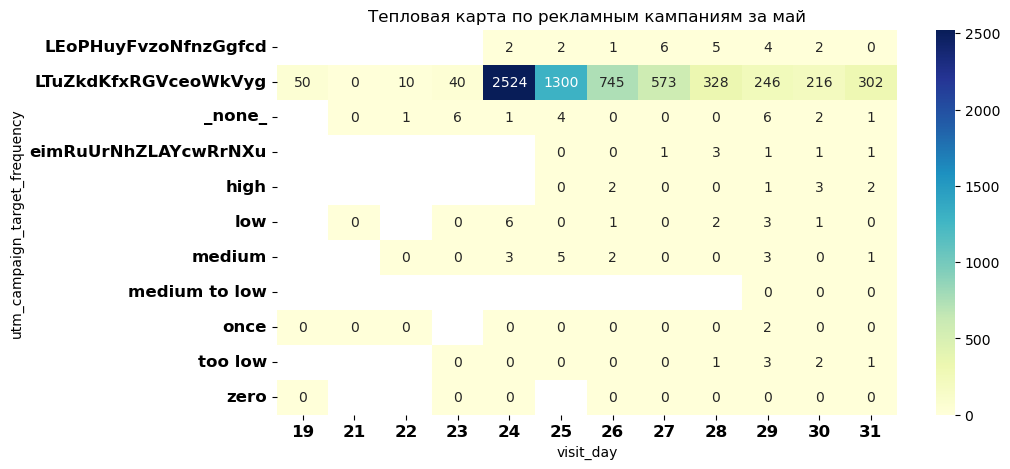

In [185]:
ga_tg_piv_utm_campaign = ga_tg[ga_tg.visit_month==5].pivot_table(
    index='utm_campaign_target_frequency', columns='visit_day', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(10,5))
plt.title('Тепловая карта по рекламным кампаниям за май')
sns.heatmap(data=ga_tg_piv_utm_campaign,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

При проведении рекламной кампании LTuZkdKfxRGVceoWkVyg замечена особая целевая активность 24 числа.

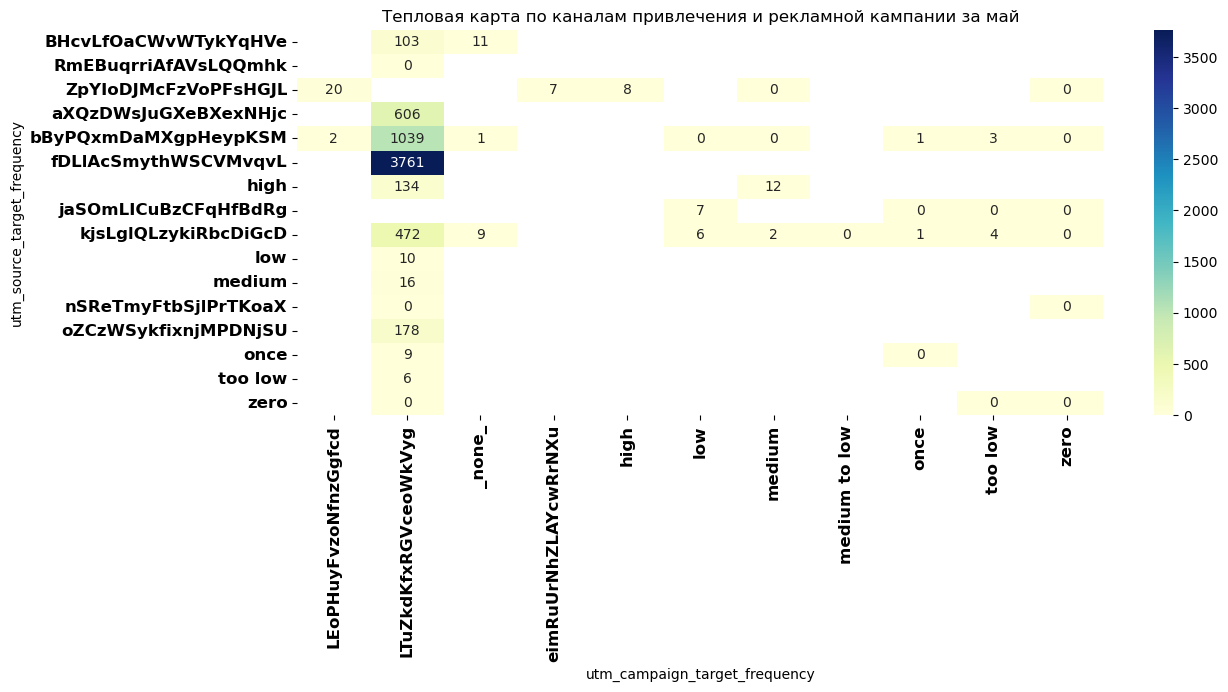

In [186]:
ga_tg_piv_source_campaign = ga_tg[ga_tg.visit_month==5].pivot_table(index='utm_source_target_frequency', columns='utm_campaign_target_frequency', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(13,5))
plt.title('Тепловая карта по каналам привлечения и рекламной кампании за май')
sns.heatmap(data=ga_tg_piv_source_campaign,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

Также у рекламной кампании LTuZkdKfxRGVceoWkVyg тесная связь с указанным ранее источником привлечения fDLlAcSmythWSCVMvqvL.

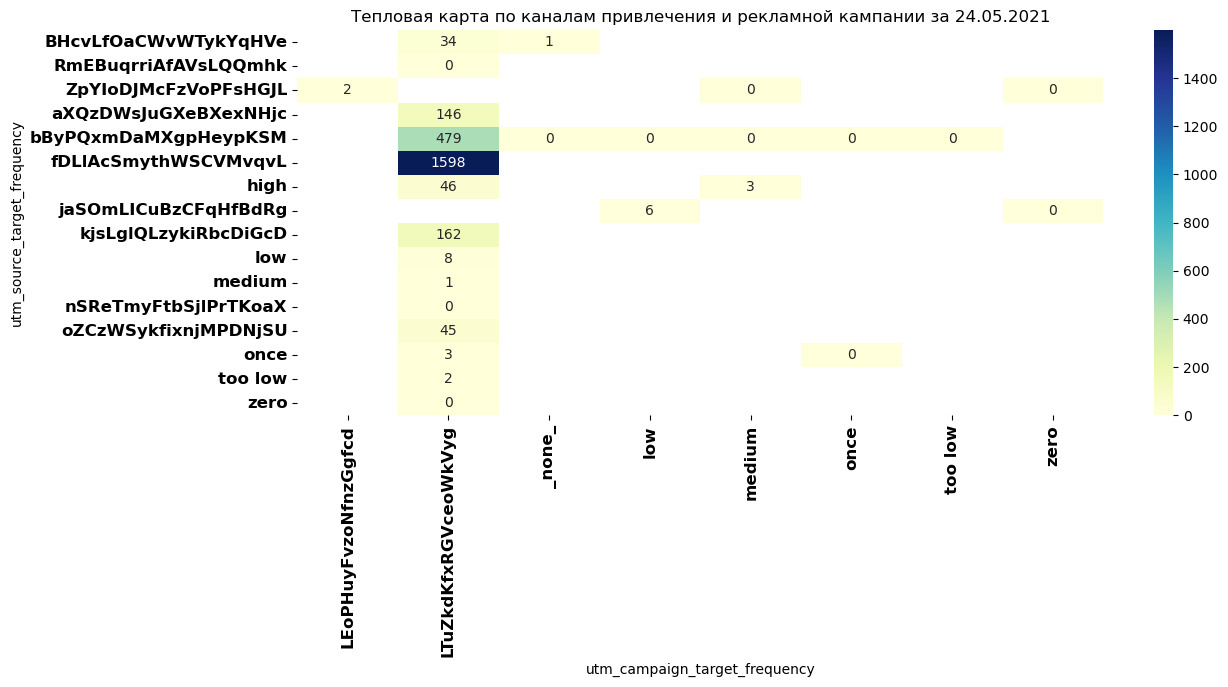

In [187]:
ga_tg_piv_source_campaign = ga_tg[ga_tg.visit_date=='2021-05-24'].pivot_table(index='utm_source_target_frequency', columns='utm_campaign_target_frequency', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(13,5))
plt.title('Тепловая карта по каналам привлечения и рекламной кампании за 24.05.2021')
sns.heatmap(data=ga_tg_piv_source_campaign,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

Та же связь 24.05, которая свидетельствует об успешной рекламной кампании в этот день, которая привлекла много целевых пользователей.

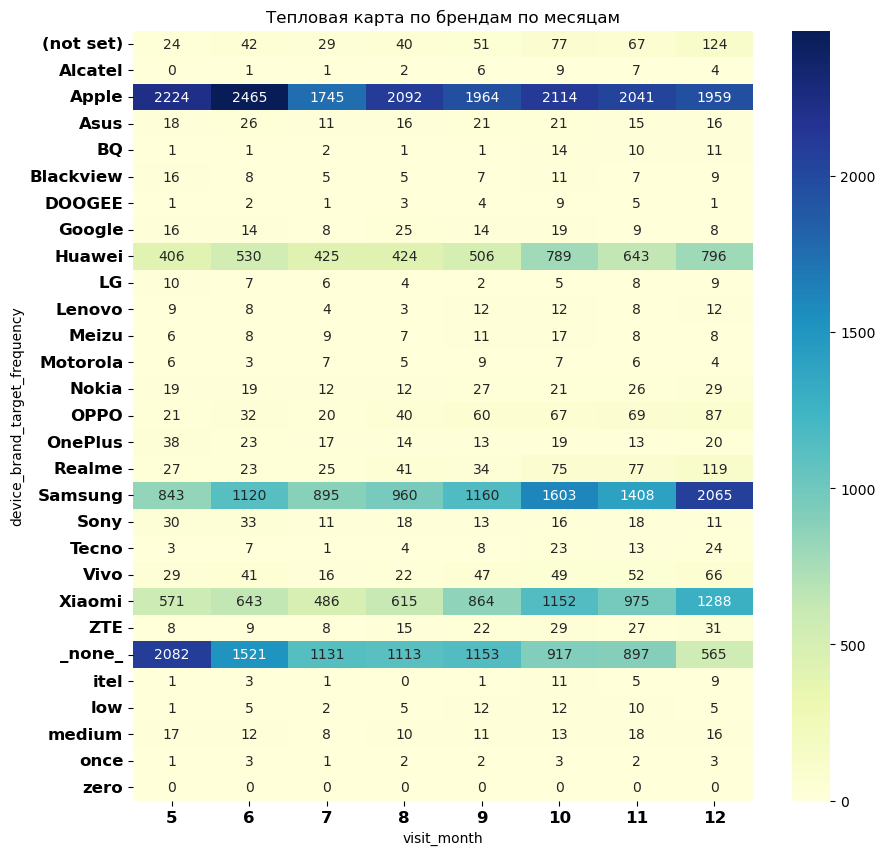

In [188]:
ga_tg_piv_brands = ga_tg.pivot_table(
    index='device_brand_target_frequency', columns='visit_month', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(10,10))
plt.title('Тепловая карта по брендам по месяцам')
sns.heatmap(data=ga_tg_piv_brands,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

Выделены самые популярные бренды: Apple, Huawei, Samsung и Xiaomi. Распределение целевых событий бренда Apple практически равномерное за весь период, а у остальных брендов количество целевых событий увеличивается каждый месяц, пик приходится на октябрь и декабрь.

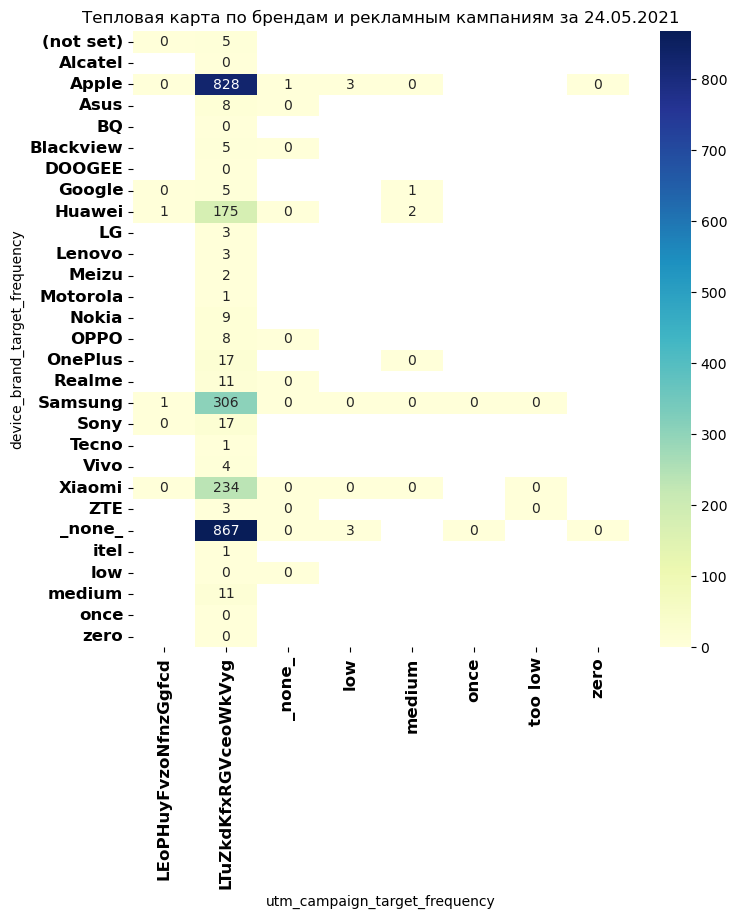

In [189]:
ga_tg_piv_brands_campaign = ga_tg[ga_tg.visit_date=='2021-05-24'].pivot_table(
    index='device_brand_target_frequency', columns='utm_campaign_target_frequency', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(8,8))
plt.title('Тепловая карта по брендам и рекламным кампаниям за 24.05.2021')
sns.heatmap(data=ga_tg_piv_brands_campaign,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

Среди известных, пользователи устройств Apple больше всего участвовали в данной рекламной кампании 24.05.

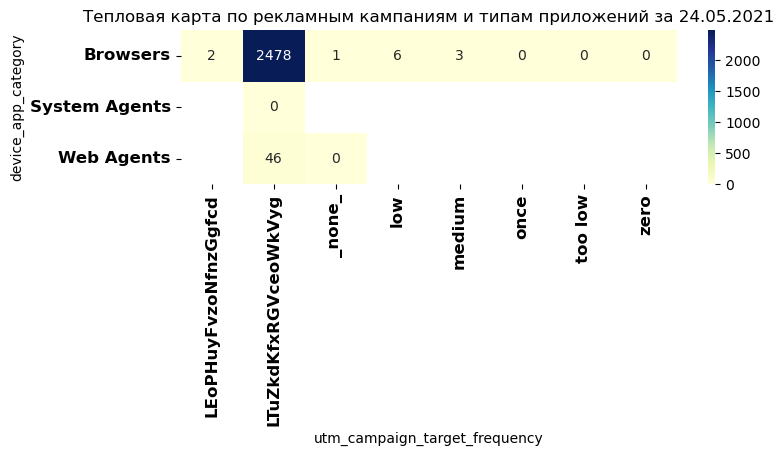

In [193]:
ga_tg_piv_app_campaign = ga_tg[ga_tg.visit_date=='2021-05-24'].pivot_table(
    index='device_app_category', columns='utm_campaign_target_frequency', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(8,2))
plt.title('Тепловая карта по рекламным кампаниям и типам приложений за 24.05.2021')
sns.heatmap(data=ga_tg_piv_app_campaign,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

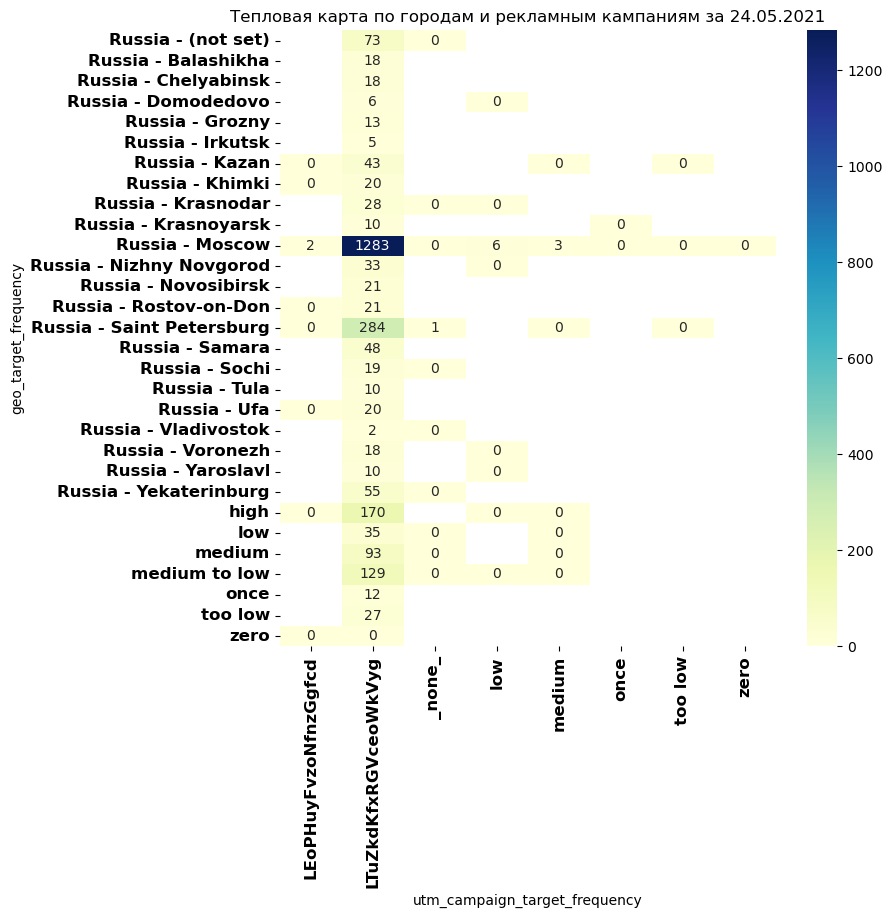

In [197]:
ga_tg_piv_geo_campaign = ga_tg[ga_tg.visit_date=='2021-05-24'].pivot_table(
    index='geo_target_frequency', columns='utm_campaign_target_frequency', values='event_session_target', aggfunc='sum')

plt.figure(figsize=(8,8))
plt.title('Тепловая карта по городам и рекламным кампаниям за 24.05.2021')
sns.heatmap(data=ga_tg_piv_geo_campaign,
           annot=True,
           fmt='.0f',
           cmap="YlGnBu")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

plt.show()

Большинство пользователей заходили на сайт преимущественно из города Москвы с помощью браузеров на устройствах Apple через источник привлечения fDLlAcSmythWSCVMvqvL с органическим типом привлечения (none), на целевое действие которых повлияла проведенная рекламная кампания LTuZkdKfxRGVceoWkVyg.

## Modelling

### Преобразование категориальных переменных

In [2]:
# ga_tg = pd.read_csv('final_work_feature_eng.csv')

In [6]:
ga_tg.columns

Index(['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number',
       'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent',
       'utm_keyword', 'device_category', 'device_os', 'device_brand',
       'device_screen_resolution', 'device_browser', 'geo_country', 'geo_city',
       'event_session_target', 'visit_hour', 'uninformative_session',
       'visit_month', 'visit_day', 'visit_week_day', 'device_app_category',
       'organic_traffic', 'social_network', 'device_anomaly',
       'utm_source_target_frequency', 'utm_medium_target_frequency',
       'utm_campaign_target_frequency', 'utm_adcontent_target_frequency',
       'utm_keyword_target_frequency', 'device_os_target_frequency',
       'device_brand_target_frequency', 'device_screen_target_frequency',
       'device_browser_target_frequency', 'geo_target_frequency'],
      dtype='object')

In [7]:
# Удаление колонок, которые не будут участвовать в обучении

df_ga_tg = ga_tg.drop(columns=['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number',
       'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent','utm_keyword',
       'device_os', 'device_brand', 'device_screen_resolution', 'device_browser', 'geo_country', 'geo_city'])
print(df_ga_tg.shape)
df_ga_tg.head()

(1732266, 21)


,device_category,event_session_target,visit_hour,uninformative_session,visit_month,visit_day,visit_week_day,device_app_category,organic_traffic,social_network,...,utm_source_target_frequency,utm_medium_target_frequency,utm_campaign_target_frequency,utm_adcontent_target_frequency,utm_keyword_target_frequency,device_os_target_frequency,device_brand_target_frequency,device_screen_target_frequency,device_browser_target_frequency,geo_target_frequency
0,mobile,0,14,0,11,24,2,Browsers,0,0,...,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei,mobile 360x720,Chrome,too low
1,mobile,0,8,0,11,14,6,Browsers,0,1,...,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,Android,Samsung,mobile 385x854,Samsung Internet,Russia - Moscow
2,mobile,0,2,0,12,28,1,Browsers,0,0,...,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,Android,Huawei,mobile 360x720,Chrome,Russia - Krasnoyarsk
3,mobile,0,5,0,5,29,5,Browsers,0,0,...,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android,Xiaomi,mobile - high,Chrome,Russia - Moscow
4,mobile,0,5,0,5,29,5,Browsers,0,0,...,kjsLglQLzykiRbcDiGcD,cpc,_none_,low,_none_,Android,Xiaomi,mobile - high,Chrome,Russia - Moscow


In [8]:
ohe_columns = df_ga_tg[['device_category', 'visit_month', 'visit_day', 'visit_week_day', 'visit_hour', 'device_app_category', 
       'utm_source_target_frequency', 'utm_medium_target_frequency', 'utm_campaign_target_frequency',
       'utm_adcontent_target_frequency', 'utm_keyword_target_frequency',
       'device_os_target_frequency', 'device_brand_target_frequency',
       'device_screen_target_frequency', 'device_browser_target_frequency',
       'geo_target_frequency']]

In [9]:
ohe = OneHotEncoder(sparse_output=False)
ohe

,categories,'auto'
,drop,None
,sparse_output,False
,dtype,<class 'numpy.float64'>
,handle_unknown,'error'
,min_frequency,None
,max_categories,None
,feature_name_combiner,'concat'


In [10]:
ohe.fit(ohe_columns)

,categories,'auto'
,drop,None
,sparse_output,False
,dtype,<class 'numpy.float64'>
,handle_unknown,'error'
,min_frequency,None
,max_categories,None
,feature_name_combiner,'concat'


In [11]:
ohe_cat = ohe.transform(ohe_columns)

In [12]:
ohe_cat.shape

(1732266, 311)

In [ ]:
df_ga_tg[ohe.get_feature_names_out()] = ohe_cat

In [14]:
df_ga_tg.columns[0:30]

Index(['device_category', 'event_session_target', 'visit_hour',
       'uninformative_session', 'visit_month', 'visit_day', 'visit_week_day',
       'device_app_category', 'organic_traffic', 'social_network',
       'device_anomaly', 'utm_source_target_frequency',
       'utm_medium_target_frequency', 'utm_campaign_target_frequency',
       'utm_adcontent_target_frequency', 'utm_keyword_target_frequency',
       'device_os_target_frequency', 'device_brand_target_frequency',
       'device_screen_target_frequency', 'device_browser_target_frequency',
       'geo_target_frequency', 'device_category_desktop',
       'device_category_mobile', 'device_category_tablet', 'visit_month_5',
       'visit_month_6', 'visit_month_7', 'visit_month_8', 'visit_month_9',
       'visit_month_10'],
      dtype='object')

In [15]:
df_ml = df_ga_tg.drop(columns=['device_category', 'visit_month', 'visit_day', 'visit_week_day', 'visit_hour', 'device_app_category',
       'utm_source_target_frequency', 'utm_medium_target_frequency', 'utm_campaign_target_frequency',
       'utm_adcontent_target_frequency', 'utm_keyword_target_frequency',
       'device_os_target_frequency', 'device_brand_target_frequency',
       'device_screen_target_frequency', 'device_browser_target_frequency', 'geo_target_frequency'])
df_ml.head()

,event_session_target,uninformative_session,organic_traffic,social_network,device_anomaly,device_category_desktop,device_category_mobile,device_category_tablet,visit_month_5,visit_month_6,...,geo_target_frequency_Russia - Voronezh,geo_target_frequency_Russia - Yaroslavl,geo_target_frequency_Russia - Yekaterinburg,geo_target_frequency_high,geo_target_frequency_low,geo_target_frequency_medium,geo_target_frequency_medium to low,geo_target_frequency_once,geo_target_frequency_too low,geo_target_frequency_zero
0,0,0,0,0,0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0,0,0,1,0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,0,0,0,0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0,0,0,0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,0,0,0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Моделирование

In [16]:
X = df_ml.drop(['event_session_target'], axis=1)
Y = df_ml['event_session_target']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42)

x_train.shape, x_test.shape

((1212586, 315), (519680, 315))

##### <span style="color: brown;"> Модель Случайного леса </spam>

In [24]:
# Параметры по умолчанию

start = time.time()

clf_rf = RandomForestClassifier()

clf_rf.fit(x_train, y_train)

pred_train = clf_rf.predict(x_train)
pred_test = clf_rf.predict(x_test)

print('roc_auc_score train:', roc_auc_score(y_train, clf_rf.predict_proba(x_train)[:, 1]))
print('roc_auc_score test:', roc_auc_score(y_test, clf_rf.predict_proba(x_test)[:, 1]))

print(time.time() - start)

roc_auc_score train: 0.9980744620906019
roc_auc_score test: 0.6280258009808891
2392.7953112125397


In [26]:
# Параметры, полученные в результате тюнинга

start = time.time()

clf_rf = RandomForestClassifier(random_state=42, n_estimators=50, max_depth=15 )

clf_rf.fit(x_train, y_train)

pred_train = clf_rf.predict(x_train)
pred_test = clf_rf.predict(x_test)

print('roc_auc_score train:', roc_auc_score(y_train, clf_rf.predict_proba(x_train)[:, 1]))
print('roc_auc_score test:', roc_auc_score(y_test, clf_rf.predict_proba(x_test)[:, 1]))

print(time.time() - start)

roc_auc_score train: 0.764919283190794
roc_auc_score test: 0.6884129276362649
439.853303194046


##### <span style="color: brown;"> Модель Логистической регрессии </spam>

In [17]:
# Параметры по умолчанию

start = time.time()

logreg = LogisticRegression()

logreg.fit(x_train, y_train)

pred_train = logreg.predict(x_train)
pred_test = logreg.predict(x_test)

print('roc_auc_score train:', roc_auc_score(y_train, logreg.predict_proba(x_train)[:, 1]))
print('roc_auc_score test:', roc_auc_score(y_test, logreg.predict_proba(x_test)[:, 1]))
print('confusion_matrix:\n', confusion_matrix(y_test, pred_test))

print(time.time() - start)

roc_auc_score train: 0.6884506698784755
roc_auc_score test: 0.6845993592685832
confusion_matrix:
 [[504537      0]
 [ 15143      0]]
137.5195004940033


In [18]:
# Параметры, полученные в результате тюнинга

start = time.time()

logreg = LogisticRegression(C=2, max_iter=500, random_state=42, class_weight='balanced')

logreg.fit(x_train, y_train)

pred_train = logreg.predict(x_train)
pred_test = logreg.predict(x_test)

print('roc_auc_score train:', roc_auc_score(y_train, logreg.predict_proba(x_train)[:, 1]))
print('roc_auc_score test:', roc_auc_score(y_test, logreg.predict_proba(x_test)[:, 1]))
print('confusion_matrix:\n', confusion_matrix(y_test, pred_test))

print(time.time() - start)

roc_auc_score train: 0.6907530689151867
roc_auc_score test: 0.6867954447996739
confusion_matrix:
 [[302330 202207]
 [  5138  10005]]
189.2611882686615


In [33]:
# Кросс-валидация модели Логистической регрессии

cross_validate(logreg, X, Y, cv=5, scoring='roc_auc')

{'fit_time': array([232.14744258, 220.71350479, 220.12870717, 247.85109591,
        232.71299052]),
 'score_time': array([3.8646071 , 3.00255418, 3.55966878, 2.6206584 , 1.53600264]),
 'test_score': array([0.68805306, 0.68749185, 0.68135123, 0.68705368, 0.6885246 ])}

### Results

В качестве моделей обучения были выбраны Логистическая регрессия и Случайный лес. Над обеими моделями был проведен тюнинг параметров, который улучшил результаты по метрике roc_auc у обеих моделей.
Несмотря на то, что значение данной метрики на тестовой выборке у Случайного леса (0.6884129276362649) немного лучше, чем у Логистической регрессии (0.6867954447996739),  модель Случайного леса склонна к переобучению. Кросс-валидация модели Логистической регрессии показала, что данная модель стабильна на разных выборках.

In [19]:
# Обучение модели Логистической регрессии на всем датасете

logreg.fit(X, Y)
print('roc_auc_score:', roc_auc_score(Y, logreg.predict_proba(X)[:, 1]))

roc_auc_score: 0.690051345979877


In [20]:
# Сохранение модели

filename = 'sberauto_logreg.pickle'

with open(filename, 'wb') as file:
    pickle.dump(logreg, file)